# ⏰ Optimal Start & Stop for HVAC: four PNNL models vs. a G36 learner vs. a one-line EMA

**When should a building's air handlers wake up so every room is comfortable right when people arrive, and how early can they shut off at night?**

This notebook explains, codes up and tests three families of "when do I turn the heat on in the morning?" algorithms:

* the **four optimal-start models** from PNNL's 2024 field study (Kim, Yu, Lutes & Katipamula, *Applied Thermal
  Engineering* 257, 124256), plus PNNL's own trick of taking the **median of all four**,
* our **G36 recovery learner** (the start logic inside our NeurIPS 2026 "v7" controller),
* a **one-line linear-rate EMA** (one learned number per zone),

plus an **optimal-stop** (coast-down) model for the evening. Every algorithm ran closed-loop in the simulator behind the
**NeurIPS 2026 Smart Buildings** challenge: 6 office buildings, 6 climates, 22 thirty-day scenarios.

<div style="border-left: 6px solid #e377c2; background: #fdf2f8; padding: 12px 18px; border-radius: 4px;">

**TL;DR: there's no single winner; it depends what you measure.**

| what you care about | winner | runner-up |
|---|---|---|
| 🏆 **Competition score** (the official whole-month score) | **G36 recovery learner (v7)**: +0.74 % vs a fixed 2 h start, worst scenario +2.5 % | PNNL median of four (+0.88 %, worst +4.9 %) |
| Energy saved at equal comfort | **PNNL median of four** (+1.76 %) | **Linear-rate EMA** (+1.60 %) |
| Comfort (fewest late mornings) | **PNNL median of four** (40 %) | Linear-rate EMA (43 %); v7 47 % |
| Predicting warm-up time | **Linear-rate EMA** (29 min average error) | PNNL Model 4 (36 min) |
| Fewest late *starts* in the replay | **v7 rule** (16 %, thanks to its ×1.25 + 15 min margin) | PNNL Model 1 (23 %) |
| Simplest to deploy (no libraries) | **Linear-rate EMA** (2 numbers, ~9 lines) | v7 start rule (2 numbers, ~14 lines) |
| Evening optimal stop | **First-order coast-down**: +3.0 % evening energy for +0.7 °F·min/zone | — |

* **Plain truth:** none of the learners beats a plain fixed 2-hour start on the competition score in this simulator; the
  differences are under 1 %. Start time here is mostly an energy-vs-comfort dial.
* **Pick v7** for the competition. **Pick the EMA** for a real controller with only basic math. **Pick the PNNL median**
  if you can run four models and care most about comfort.
</div>

## Table of contents
1. [What optimal start and stop are](#1)
2. [Data, simulator and how we score an algorithm](#2)
3. [PNNL Model 1: quadratic recovery time](#m1)
4. [PNNL Model 2: outdoor-air ratio](#m2)
5. [PNNL Model 3: regression with an outdoor-load term](#m3)
6. [PNNL Model 4: exponential (first-order) approach](#m4)
7. [Our G36 recovery learner (NeurIPS v7)](#v7)
8. [The linear-rate EMA: the simplest learner](#m0)
9. [Optimal stop: first-order coast-down](#stop)
10. [Leaderboard: who wins what](#board)
11. [Deployability: how hard is each one to run on a real controller?](#deploy) · [Best pick with only a standard math library](#stdlib)
12. [Takeaways, limitations, use it on your own building, references](#end)

<a id="1"></a>
## 1. What optimal start and stop are

Most commercial buildings set back overnight: heating setpoints drop, cooling setpoints rise, and the fans go off.
In the morning the system has to **recover** the zones to the occupied comfort band before people walk in.

* A **fixed schedule** starts every air handler (AHU) the same 60 to 120 minutes early, every day. That's safe on the
  coldest Monday, but on a mild Thursday the building sits comfortable and empty for an hour, burning energy.
* **Optimal start** predicts, each morning, *how long this zone needs to recover today* and starts just that much
  before occupancy. The prediction is learned from past mornings.
* **Optimal stop** is the evening mirror image: near the end of the day, if the zones will drift slowly enough to
  stay comfortable until everyone leaves, turn the AHU off a little early and **coast**.

The whole problem boils down to one number per morning, the lead time:

$$t_{\text{start}} = t_{\text{occupancy}} - \widehat{t}_{\text{recover}}(T_{\text{zone}},\,T_{\text{setpoint}},\,T_{\text{outdoor}},\ \text{history})$$

Start too late and people arrive to a cold office (a **comfort miss**). Start too early and you waste energy (**early waste**).

In [1]:
# Setup: only numpy, pandas, matplotlib (scipy optional). Runs in well under a minute.
import math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 2)

plt.rcParams.update({
    "figure.figsize": (10, 4.6), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.fontsize": 9.5, "legend.frameon": False, "font.size": 10.5,
})

# One name and one color per algorithm, used in every chart.
NAMES = {
    "fixed_60": "Fixed 60 min", "fixed_120": "Fixed 120 min", "fixed_180": "Fixed 180 min",
    "pnnl_m1_quadratic": "PNNL M1 · quadratic", "pnnl_m2_oat_ratio": "PNNL M2 · OAT ratio",
    "pnnl_m3_regression": "PNNL M3 · regression", "pnnl_m4_exponential": "PNNL M4 · exponential",
    "pnnl_deployed_median_split": "PNNL median of M1-M4",
    "v7": "G36 recovery learner (v7)", "m0_linear_ema": "Linear-rate EMA",
}
COLORS = {
    "fixed_60": "#c7c7c7", "fixed_120": "#7f7f7f", "fixed_180": "#3f3f3f",
    "pnnl_m1_quadratic": "#1f77b4", "pnnl_m2_oat_ratio": "#ff7f0e", "pnnl_m3_regression": "#2ca02c",
    "pnnl_m4_exponential": "#d62728", "pnnl_deployed_median_split": "#9467bd",
    "v7": "#e377c2", "m0_linear_ema": "#e6a700",
}
CONTENDERS = ["pnnl_m1_quadratic", "pnnl_m2_oat_ratio", "pnnl_m3_regression", "pnnl_m4_exponential",
              "pnnl_deployed_median_split", "v7", "m0_linear_ema"]
KEEP = ["fixed_60", "fixed_120", "fixed_180"] + CONTENDERS   # fixed schedules are the reference line only
STOP_NAMES = {"no_early_stop": "No early stop", "first_order_coast": "First-order coast (ours)",
              "vavrl_const_drift": "Constant drift 0.35 °F/h", "v6": "G36 stop (v6/v7 controller)"}
STOP_COLORS = {"no_early_stop": "#7f7f7f", "first_order_coast": "#e6a700", "vavrl_const_drift": "#1f77b4", "v6": "#8c564b"}
K2F = 1.8  # 1 K of temperature difference = 1.8 °F

<a id="2"></a>
## 2. Data, simulator and how we score an algorithm

**Simulator.** The NeurIPS 2026 Smart Buildings challenge uses Google's [Smart Buildings simulator](https://github.com/google/sbsim), a physics-based model of
real office buildings: multiple AHUs, 30 to 85 VAV zones with reheat, real weather, randomized occupancy and a
utility-cost model. Each **scenario** is one building with one 30-day weather strip, stepped every 5 minutes.
Occupied band: 69.5 to 75.0 °F (294 to 297 K), 06:00 to 19:00.

**What changes between runs.** The same standard control sequence (ASHRAE Guideline 36, "G36") runs the plant in every
run. Only two decisions are swapped: **when each air handler starts warming up (or cooling down) in the morning**, and
**whether it may shut off early** in the evening. One exception: the G36 recovery learner (v7) is our full NeurIPS
competition controller, so it runs with its own start, stop and plant logic.

**Learning is online only.** Every model starts empty on day 1 and learns only from mornings it has already seen.
The first 7 days are simulated but not scored (warm-up). No model is trained on the future.

**Metrics** (per AHU per morning, then averaged):

| metric | meaning | better |
|---|---|---|
| **lead** | minutes of warm-up before occupancy | – |
| **late % (1 °F tol.)** | share of mornings a recoverable zone was still more than 1 °F outside the band at occupancy (PNNL's allowable deviation) | lower |
| **unmet** | comfort deficit summed over the first 2 h of occupancy, °F·min per zone | lower |
| **energy saved** | building $ over 4 h before to 2 h after occupancy, vs. a fixed 120-min start on the same day | higher |
| **reward gain** | the simulator's own reward (comfort regret + energy + carbon) over the same window, vs. fixed 120 min | higher |
| **competition score** | the NeurIPS/Kaggle score for the whole 30-day run, shown as % worse than fixed 120 min | lower |

**How we pick winners.** Start time is mostly a dial between energy and comfort: start later, save energy, lose comfort.
So "saves the most energy" means nothing on its own. We look at four things:

1. **Savings beyond schedule.** In each scenario, the fixed 60/120/180-minute runs trace the energy-vs-comfort curve
   that any plain schedule can reach. An algorithm only adds value if it saves *more* energy than a fixed schedule that
   delivers the *same* comfort. Positive = beats every fixed schedule.
2. **Reward regret.** Per scenario, the algorithm's reward minus the best algorithm's reward (0 is best).
3. **Competition score.** The official score over the whole month (energy, carbon and comfort, every 5 minutes).
4. **Worst case.** The worst scenario on each of the above, because a controller that's great on average and terrible in
   one climate is a support call waiting to happen.

In [2]:
# Load the small result files (about 0.4 MB). Works from the repo, from an attached Kaggle dataset, or downloads.
FILES = ["start_ahu_days.csv.gz", "start_days.csv.gz", "runs.csv", "stop_ahu_days.csv.gz", "stop_days.csv.gz",
         "recovery_events.csv.gz", "recovery_traces.csv.gz", "example_morning.csv"]
RAW = "https://raw.githubusercontent.com/bbartling/hvac-optimal-start-math-playground/develop/data/"

def find_data_dir():
    for d in [Path("data"), Path("../data"), *sorted(Path("../input").glob("*")), *sorted(Path("../input").glob("*/data"))]:
        if (d / FILES[0]).exists():
            return d
    return None

DATA = find_data_dir()
def load(name):
    if DATA is not None:
        return pd.read_csv(DATA / name)
    return pd.read_csv(RAW + name)   # fallback: fetch the same file from GitHub

A   = load("start_ahu_days.csv.gz")    # one row per run x scored morning x AHU
D   = load("start_days.csv.gz")        # one row per run x scored morning (building energy and reward)
RUN = load("runs.csv")                 # one row per simulation
SA, SD = load("stop_ahu_days.csv.gz"), load("stop_days.csv.gz")   # dedicated optimal-stop experiment
EV, TR = load("recovery_events.csv.gz"), load("recovery_traces.csv.gz")  # recorded recoveries for model fitting
EX  = load("example_morning.csv")
A, D, RUN = (t[t.start.isin(KEEP)].reset_index(drop=True) for t in (A, D, RUN))
for c in ["unmet", "unmet_people"]:
    A[c] = A[c] * K2F                  # K·min -> °F·min
print(f"{RUN.shape[0]} simulations of these algorithms | {A.scenario.nunique()} scenarios | {A.scenario.str[:2].nunique()} buildings | "
      f"{A.city.nunique()} climates | {len(A):,} scored AHU-mornings | {EV.shape[0]:,} recorded recoveries")

152 simulations of these algorithms | 22 scenarios | 6 buildings | 6 climates | 13,952 scored AHU-mornings | 1,163 recorded recoveries


### What a morning looks like

Below is one November morning in Denver for one AHU: the shaded band is the comfort band, the line is the average zone
temperature (the ribbon spans the coldest to warmest zone), and the bar marks when warm-up was running. The fixed
schedule starts two hours early and the zones are comfortable well before 06:00. The learned EMA waits an hour longer,
so it uses less energy, and the zones still get there right around 06:00.

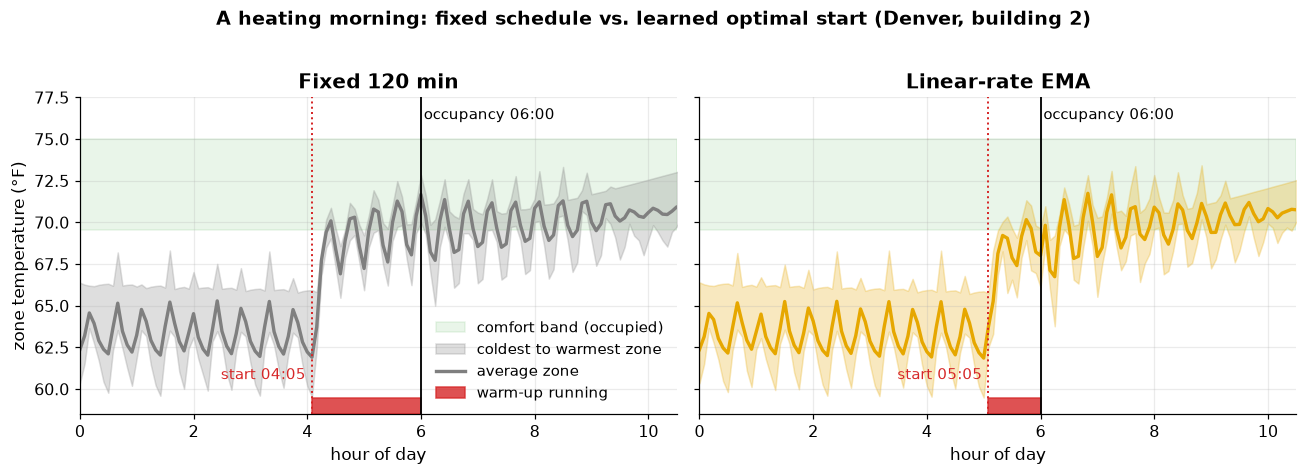

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, st in zip(axes, ["fixed_120", "m0_linear_ema"]):
    e = EX[EX.start == st].copy(); e["time"] = pd.to_datetime(e.time)
    h = e.time.dt.hour + e.time.dt.minute / 60
    ax.axhspan(69.53, 75.0, color="#2ca02c", alpha=0.10, label="comfort band (occupied)")
    ax.fill_between(h, e.zmin_f, e.zmax_f, color=COLORS[st], alpha=0.25, label="coldest to warmest zone")
    ax.plot(h, e.zmean_f, color=COLORS[st], lw=2.2, label="average zone")
    w = h[e.warm == 1]
    if len(w):
        ax.axvspan(w.min(), w.max() + 5 / 60, ymin=0, ymax=0.05, color="#d62728", alpha=0.8, label="warm-up running")
        ax.axvline(w.min(), color="#d62728", ls=":", lw=1.3)
        ax.annotate(f"start {int(w.min()):02d}:{int(round((w.min() % 1) * 60)):02d}", (w.min(), 60.6), xytext=(-4, 0), ha="right",
                    textcoords="offset points", color="#d62728", fontsize=9.5)
    ax.axvline(6, color="k", lw=1.2); ax.text(6.05, 76.2, "occupancy 06:00", fontsize=9.5)
    ax.set_title(NAMES[st]); ax.set_xlabel("hour of day"); ax.set_xlim(0, 10.5); ax.set_ylim(58.5, 77.5)
axes[0].set_ylabel("zone temperature (°F)"); axes[0].legend(loc="lower right")
fig.suptitle("A heating morning: fixed schedule vs. learned optimal start (Denver, building 2)", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### Shared scoring helpers

Every algorithm section uses the same two helpers: one scores a closed-loop run (lateness, comfort, energy and reward
against a fixed 120-minute start on the same day), the other replays recorded mornings offline so we can plot predicted
vs. actual recovery time.

In [4]:
def q90(x): return float(np.nanpercentile(x, 90)) if len(x) else np.nan

# Energy / reward paired with the fixed-120 run on the same scenario and date.
_base = D[D.start == "fixed_120"][["scenario", "date", "morning_energy", "morning_reward"]].rename(
    columns={"morning_energy": "e0", "morning_reward": "r0"})
DP = D.merge(_base, on=["scenario", "date"])
DP["saved_pct"] = 100 * (DP.e0 - DP.morning_energy) / DP.e0
DP["reward_gain"] = DP.morning_reward - DP.r0

def score(by=("start",), a=A, d=DP):
    by = list(by)
    s = a.groupby(by).agg(mornings=("lead", "size"), lead_p50=("lead", "median"),
                          late_pct=("late_tol", lambda x: 100 * (x > 0).mean()), late_p90=("late_tol", q90),
                          unmet=("unmet", "mean"))
    e = d.groupby(by).agg(saved_pct=("saved_pct", "mean"), reward_gain=("reward_gain", "mean"))
    return s.join(e)

def F(t, default="{:.1f}", **over):
    # one formatter per column (behaves the same on every pandas version)
    cols = t.columns if hasattr(t, "columns") else t.index
    return {c: over.get(c, default) for c in cols}

COLS = {"mornings": "AHU-mornings", "lead_p50": "lead p50 (min)", "late_pct": "late % (1 °F tol.)",
        "late_p90": "late p90 (min)", "unmet": "unmet (°F·min/zone)", "saved_pct": "energy saved vs fixed 120 (%)",
        "reward_gain": "reward gain vs fixed 120"}
def show(t, caption=None, fmt=None):
    t = t.rename(columns=COLS).rename(index=lambda i: NAMES.get(i, i))
    f = F(t, fmt or "{:.1f}")
    f.update({c: v for c, v in {"AHU-mornings": "{:,.0f}", "reward gain vs fixed 120": "{:+.3f}"}.items() if c in t})
    st = t.style.format(f, na_rep="–")
    if caption: st = st.set_caption(caption)
    display(st)

# ---- offline replay of recorded recoveries ----------------------------------------------------------
# Each event: one AHU's critical (furthest-from-setpoint) zone on one morning of a fixed-180 run, with its
# trajectory from the moment warm-up began (°F, 5-min samples) until it reached the setpoint.
TRAJ = {k: g[["minute", "temp_f"]].to_numpy() for k, g in TR.groupby("event")}
EV = EV.sort_values(["scenario", "ahu", "date"]).reset_index(drop=True)

def deficit(mode, temp, target): return max(0.0, target - temp) if mode == "heat" else max(0.0, temp - target)

def replay(make_model, max_lead=180.0):
    """Feed each AHU's mornings to a fresh model in date order: predict first, then learn. Returns predictions."""
    out = []
    for _, g in EV.groupby(["scenario", "ahu"], sort=False):
        m = make_model()
        for e in g.itertuples():
            tr = TRAJ[e.event]
            p = m.predict(e.mode, e.start_temp_f, e.target_f, e.oat_f, e.post_weekend)
            p = max_lead if p is None else float(np.clip(p, 0, max_lead))
            # where would the zone be if we had started p minutes early? (for M3's day-to-day correction)
            k = min(int(round(p / 5)), len(tr) - 1)
            short = deficit(e.mode, tr[k, 1], e.target_f) if p < tr[-1, 0] or np.isnan(e.minutes_to_target) else 0.0
            if np.isfinite(e.minutes_to_target):
                m.update(dict(mode=e.mode, start=e.start_temp_f, target=e.target_f, oat=e.oat_f, oat_mean=e.oat_mean_f,
                              t=e.minutes_to_target, traj=tr, arrival_error=short))
            out.append((e.event, e.city, e.mode, p, e.minutes_to_target))
    return pd.DataFrame(out, columns=["event", "city", "mode", "pred", "actual"])

def replay_stats(r):
    ok = r.dropna(subset=["actual"])
    err = ok.pred - ok.actual
    return pd.Series({"recoveries": len(ok), "MAE (min)": err.abs().mean(), "bias (min)": err.mean(),
                      "late starts %": 100 * (err < -5).mean(), "within ±15 min %": 100 * (err.abs() <= 15).mean()})

def show_replay(key):
    t = replay_stats(REPLAY[key]).to_frame(NAMES[key]).T
    display(t.style.format(F(t, "{:.1f}", recoveries="{:,.0f}")).set_caption("Offline replay of recorded recoveries (predict, then learn)"))

def pnnl_ema(values):
    """PNNL's deployed EMA over a window of daily parameters: newest weighted most, smoothing min(1, 4/(n+1))."""
    n = len(values); s = min(1.0, 4.0 / (n + 1)); rev = values[::-1]
    return sum(rev[i] * s * (1 - s) ** i for i in range(n)) + rev[-1] * (1 - s) ** n

def minutes_per_first_degree(ev, degree=1.0):
    sign = 1 if ev["mode"] == "heat" else -1
    for t, temp in ev["traj"]:
        gained = sign * (temp - ev["start"])
        if t > 0 and gained >= degree:
            return t / gained
    return None

def evaluation_plots(key, rep):
    """Two panels: offline predicted vs actual recovery time, closed-loop arrival error vs fixed 120."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))
    ok = rep.dropna(subset=["actual"])
    for mode, mk in [("heat", "o"), ("cool", "^")]:
        s = ok[ok["mode"] == mode]
        a1.scatter(s.actual, s.pred, s=14, alpha=0.45, marker=mk, color=COLORS[key], label=f"{mode}ing mornings")
    lim = max(60, np.nanpercentile(ok.actual, 99), np.nanpercentile(ok.pred, 99)) * 1.05
    a1.plot([0, lim], [0, lim], "k--", lw=1, label="perfect prediction")
    a1.set_xlim(0, lim); a1.set_ylim(0, lim); a1.legend(loc="upper left")
    a1.set_xlabel("actual recovery time (min)"); a1.set_ylabel("predicted recovery time (min)")
    a1.set_title("Offline replay: predicted vs. actual")
    bins = np.arange(-120, 245, 10)
    for k, alpha in [("fixed_120", 0.35), (key, 0.75)]:
        x = A[A.start == k].arrival.clip(-120, 240)
        a2.hist(x, bins=bins, density=True, alpha=alpha, color=COLORS[k], label=NAMES[k])
    a2.axvline(0, color="k", lw=1)
    a2.set_xlabel("arrival error (min): < 0 early (wasted run), > 0 late; last bar = 4 h or more")
    a2.set_ylabel("share of AHU-mornings"); a2.set_title("Closed loop: when the last zone got comfortable"); a2.legend(loc="upper center")
    a2.yaxis.set_major_formatter(PercentFormatter(xmax=0.1, decimals=0))
    plt.tight_layout(); plt.show()

def climate_table(key):
    t = score(["start", "city"]).loc[[key, "fixed_120"]].reset_index()
    t["algorithm"] = t.start.map(NAMES)
    t = t.set_index(["city", "algorithm"]).drop(columns="start").sort_index()
    show(t, caption=f"{NAMES[key]} vs. a fixed 120-min start, by climate (closed loop)")

<a id="m1"></a>
## 3. PNNL Model 1: quadratic recovery time

### How it works
**Intuition.** The bigger the temperature gap at start-up, the longer recovery takes, and it grows faster than linearly
because the zone's heat loss grows as it warms. Model 1 ignores the weather entirely; it only looks at the gap.

$$\widehat{t} = a\,\big(T_{sp} - T_{z,0}\big)^2 + b$$

* $b$ = minutes per degree over the **first** degree of recovery (start-up lag: fans spinning up, coils warming).
* $a$ = the extra curvature: from yesterday's actual time $t_{act}$ and gap $\Delta T_0$, $a = (t_{act} - b)/\Delta T_0^2$
  (if $t_{act} - b < 1$, PNNL uses $a = t_{act}/(10\,\Delta T_0)$).

**Inputs:** zone temperature, occupied setpoint. **Fitting:** each morning yields one $(a, b)$ pair; the last 8 days are
kept and blended with PNNL's exponential moving average (newest day weighted most).

**Worked example.** With $b = 6$ min and $a = 1.5$ min/°F², a 5 °F gap needs $1.5 \cdot 25 + 6 = 43.5$ minutes.

**When it works / when it fails.** Works where recovery is dominated by the zone itself (interior zones, mild weather).
Fails when the weather changes overnight: a cold snap makes recovery slower at the same gap, and Model 1 can't see it.

In [5]:
class PNNLModel1:
    name = "pnnl_m1_quadratic"
    def __init__(self, window=8): self.a, self.b, self.w = {"heat": [], "cool": []}, {"heat": [], "cool": []}, window
    def predict(self, mode, temp, target, oat, post_weekend=False):
        d = deficit(mode, temp, target)
        if d <= 0: return 0.0
        if not self.a[mode]: return None                 # no history yet -> planner uses the max lead
        return pnnl_ema(self.a[mode]) * d * d + pnnl_ema(self.b[mode])
    def update(self, ev):
        t, d0, b = ev["t"], deficit(ev["mode"], ev["start"], ev["target"]), minutes_per_first_degree(ev)
        if not t or d0 <= 0 or b is None: return
        a = (t - b) / d0 ** 2 if t - b >= 1 else t / (10 * d0)
        self.a[ev["mode"]] = (self.a[ev["mode"]] + [a])[-self.w:]
        self.b[ev["mode"]] = (self.b[ev["mode"]] + [b])[-self.w:]

m = PNNLModel1(); print("worked example:", 1.5 * 5 ** 2 + 6, "min")
REPLAY = {"pnnl_m1_quadratic": replay(PNNLModel1)}

worked example: 43.5 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M1 · quadratic,"1,033",38.9,10.8,23.2,54.5


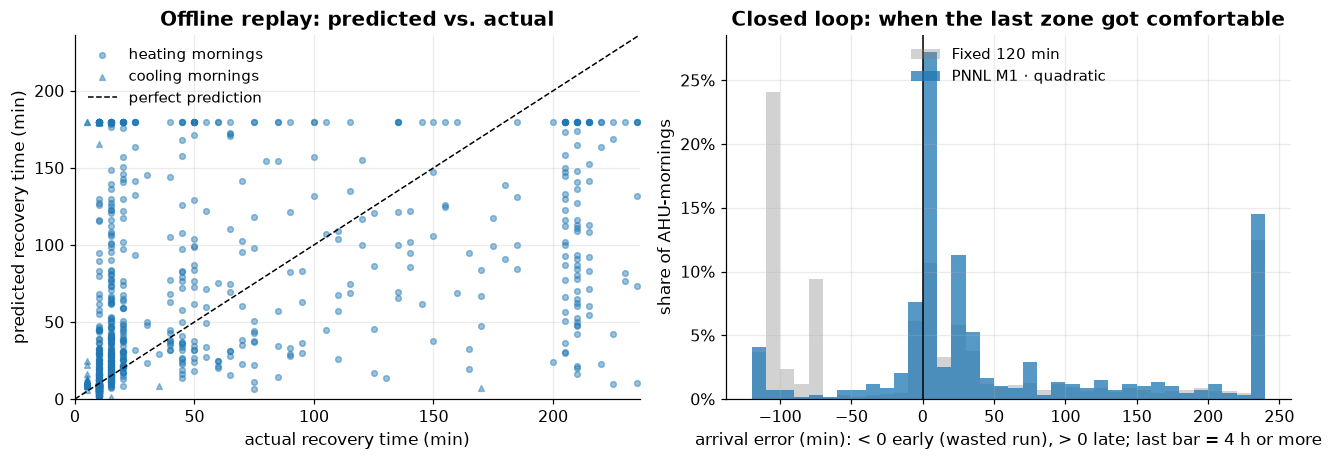

In [6]:
key = "pnnl_m1_quadratic"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** two parameters, no weather sensor, easy to explain. **Weaknesses:** blind to outdoor temperature; the
first-degree rate $b$ is noisy when the zone barely moves in the first few samples. In closed loop it starts fairly early
(lead around two hours), so it rarely saves much over a fixed schedule.

<a id="m2"></a>
## 4. PNNL Model 2: outdoor-air ratio

### How it works
**Intuition.** Learn yesterday's recovery **rate** (degrees per minute), then scale it by how much colder (or hotter) it
is today than yesterday, relative to a "design" outdoor temperature at which the unit would have to run nonstop.

$$\widehat{t} = \frac{T_{sp} - T_{z,0}}{\alpha}\cdot\frac{T_{o,ref} - T_{o}^{\,k-1}}{T_{o,ref} - T_{o}^{\,k}}, \qquad \alpha = \frac{\Delta T_{k-1}}{t_{k-1}}$$

$T_{o,ref}$ = 0 °F for heating and 100 °F for cooling (the ASHRAE values used in the paper).

**Inputs:** zone temperature, setpoint, outdoor air temperature. **Fitting:** daily $\alpha$ and the training-day OAT,
8-day window, PNNL EMA. We add one guard the paper doesn't have: the ratio is clipped to [0.25, 4] so an OAT reading near
the reference can't command a 0- or 1000-minute start (Fairbanks drops below 0 °F).

**Worked example.** Yesterday: 4 °F recovered in 40 min, so $\alpha = 0.1$ °F/min, at 30 °F outside. Today: a 5 °F gap
at 15 °F outside. Ratio $(0-30)/(0-15) = 2$, so $\widehat{t} = 5/0.1 \cdot 2 = 100$ minutes.

**When it works / when it fails.** Good for lightweight, perimeter-dominated buildings where the weather drives the load.
Fails when OAT is close to the reference (the ratio explodes) and in heavy buildings where thermal mass, not OAT, dominates.

In [7]:
class PNNLModel2:
    name = "pnnl_m2_oat_ratio"
    REF = {"heat": 0.0, "cool": 100.0}
    def __init__(self, window=8): self.rate, self.oat, self.w = {"heat": [], "cool": []}, {"heat": [], "cool": []}, window
    def predict(self, mode, temp, target, oat, post_weekend=False):
        d = deficit(mode, temp, target)
        if d <= 0: return 0.0
        if not self.rate[mode]: return None
        ref, prev = self.REF[mode], pnnl_ema(self.oat[mode])
        ratio = (ref - prev) / (ref - oat) if abs(ref - oat) > 1e-6 else 1.0
        ratio = 1.0 if not np.isfinite(ratio) or ratio <= 0 else float(np.clip(ratio, 0.25, 4.0))
        return d / pnnl_ema(self.rate[mode]) * ratio
    def update(self, ev):
        d0 = deficit(ev["mode"], ev["start"], ev["target"])
        if not ev["t"] or d0 <= 0: return
        self.rate[ev["mode"]] = (self.rate[ev["mode"]] + [d0 / ev["t"]])[-self.w:]
        self.oat[ev["mode"]] = (self.oat[ev["mode"]] + [ev["oat_mean"]])[-self.w:]

print("worked example:", 5 / 0.1 * (0 - 30) / (0 - 15), "min")
REPLAY["pnnl_m2_oat_ratio"] = replay(PNNLModel2)

worked example: 100.0 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M2 · OAT ratio,"1,033",36.2,0.3,26.1,61.5


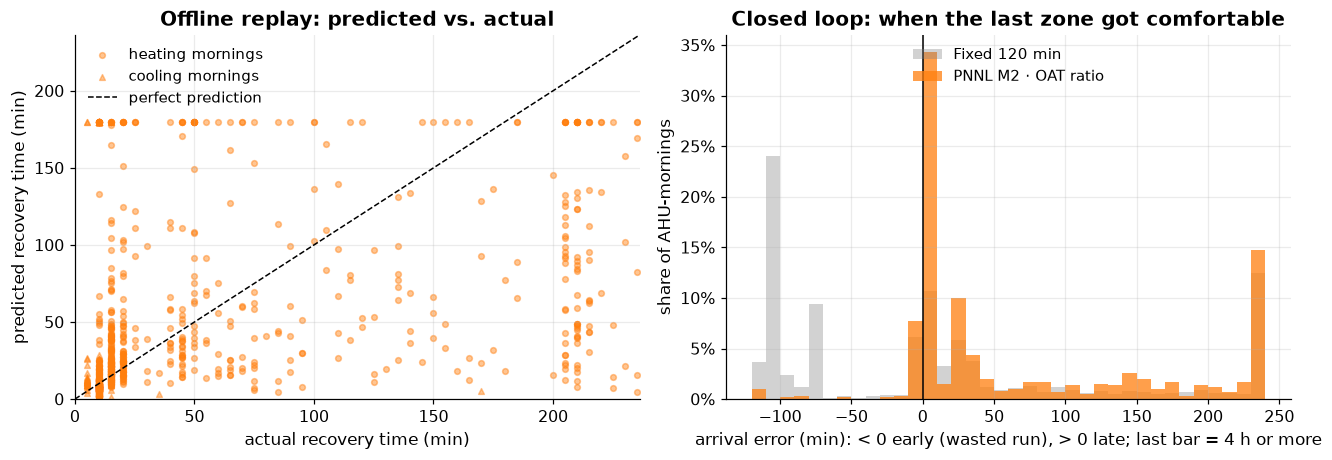

In [8]:
key = "pnnl_m2_oat_ratio"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** the only PNNL model that reacts to a change in weather from one day to the next. **Weaknesses:** the ratio
is unstable near the reference temperature and amplifies OAT sensor noise. In closed loop it trades comfort for energy
much like a 60-minute schedule.

<a id="m3"></a>
## 5. PNNL Model 3: regression with an outdoor-load term

### How it works
**Intuition.** Recovery time = a part proportional to the gap, plus a part proportional to *gap × how hard the weather is
pushing back*, plus a self-correcting nudge if yesterday's start was late or early.

$$\widehat{t} = a\,\Delta T + \frac{b}{c}\,\Delta T\,\big(T_{sp} - T_o\big) + d$$

* $a$ = minutes per degree over the first degree (like Model 1's $b$).
* $b = (t_{act} - a\,\Delta T_0)\,c\,/\,\big(\Delta T_0 (T_{sp} - T_o)\big)$, clipped at 0; $c = 10$ is PNNL's scale constant.
* $d$ = day-to-day correction: $+5$ min if yesterday the zone was more than 1 °F short at occupancy, $-5$ min if it
  overshot by more than 1 °F, reset to 0 if $|d|$ exceeds 60 min.

**Inputs:** zone temperature, setpoint, OAT, yesterday's arrival error. **Fitting:** 8-day windows for $a$ and $b$ with the
PNNL EMA; $d$ integrates the arrival feedback.

**Worked example.** $a = 6$ min/°F, $b = 0.5$, gap 5 °F, OAT 30 °F, setpoint 70 °F: $6\cdot5 + 0.05\cdot5\cdot40 + 0 = 40$ min.

**When it works / when it fails.** The paper found it the most accurate in the field. It needs a few mornings for $b$ to settle,
and the $\pm5$-minute correction is slow to react when the error is large (a Monday after a cold weekend).

In [9]:
class PNNLModel3:
    name = "pnnl_m3_regression"
    def __init__(self, window=8, c=10.0, step=5.0, reset=60.0, band=1.0):
        self.a, self.b, self.d = {"heat": [], "cool": []}, {"heat": [], "cool": []}, {"heat": 0.0, "cool": 0.0}
        self.w, self.c, self.step, self.reset, self.band = window, c, step, reset, band
    @staticmethod
    def load(mode, target, oat): return (target - oat) if mode == "heat" else (oat - target)
    def predict(self, mode, temp, target, oat, post_weekend=False):
        dT = deficit(mode, temp, target)
        if dT <= 0: return 0.0
        if not self.a[mode]: return None
        b = pnnl_ema(self.b[mode]) if self.b[mode] else 0.0
        return pnnl_ema(self.a[mode]) * dT + b * dT * max(0.0, self.load(mode, target, oat)) / self.c + self.d[mode]
    def update(self, ev):
        mode, t, d0 = ev["mode"], ev["t"], deficit(ev["mode"], ev["start"], ev["target"])
        if not t or d0 <= 0: return
        a = minutes_per_first_degree(ev) or t / d0
        L = self.load(mode, ev["target"], ev["oat"])
        b = max(0.0, (t - a * d0) * self.c / (d0 * L)) if L > 0.5 else 0.0
        self.a[mode], self.b[mode] = (self.a[mode] + [a])[-self.w:], (self.b[mode] + [b])[-self.w:]
        err, dd = ev["arrival_error"], self.d[mode]
        dd += self.step if err > self.band else (-self.step if err < -self.band else 0.0)
        self.d[mode] = 0.0 if abs(dd) > self.reset else dd

print("worked example:", 6 * 5 + 0.5 / 10 * 5 * 40, "min")
REPLAY["pnnl_m3_regression"] = replay(PNNLModel3)

worked example: 40.0 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M3 · regression,"1,033",39.1,12.8,26.9,51.5


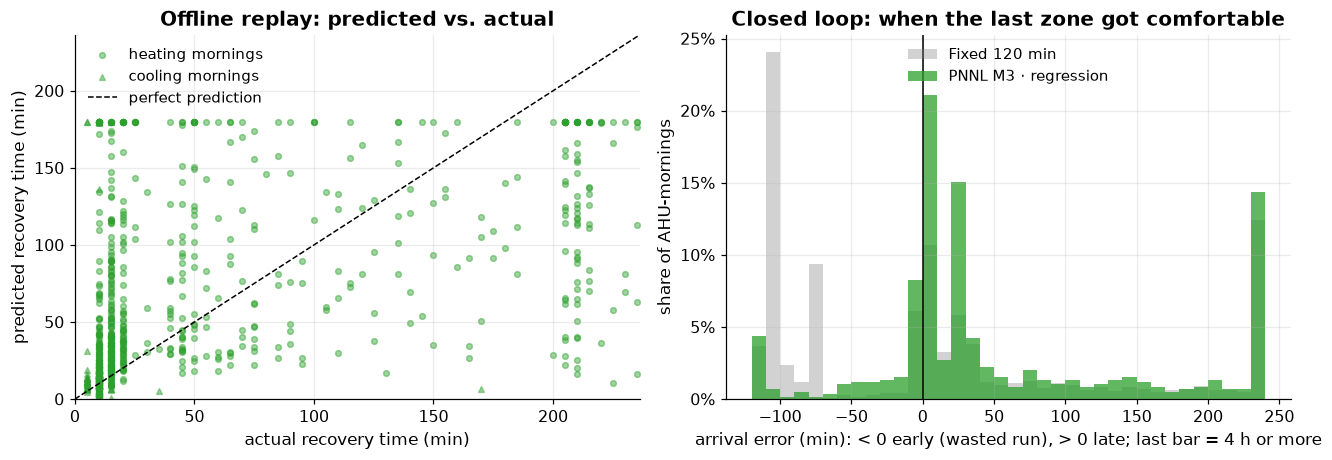

In [10]:
key = "pnnl_m3_regression"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** physically motivated (it is the linearised first-order zone model from the paper's Eq. 10), uses the weather,
and corrects itself from arrival feedback. **Weaknesses:** the outdoor term makes it start early in cold weather, so it behaves
close to a fixed two-hour schedule; the slow $\pm5$-minute correction can't fix a big miss in one day.

<a id="m4"></a>
## 6. PNNL Model 4: exponential (first-order) approach

### How it works
**Intuition.** Treat the temperature error as decaying exponentially once the unit starts: each minute the remaining gap
shrinks by a constant factor $c$. Recovery is done when the gap is inside the allowable deviation.

$$\widehat{t} = \frac{\ln(a/b)}{\ln c}, \qquad c = \frac{\sum_i e_{i-1}e_i}{\sum_i e_{i-1}^2}$$

* $a$ = allowable deviation (1 °F), $b$ = current gap, $e_i$ = gap at sample $i$ of yesterday's recovery.
* $c$ is a least-squares fit of $e_i \approx c\,e_{i-1}$ over yesterday's trajectory, converted to a per-minute factor.

**Inputs:** zone temperature and setpoint only, but it uses the whole recovery trajectory. **Fitting:** one $c$ per morning,
8-day window, PNNL EMA. Before any history, $c = e^{-1/190}$.

**Worked example.** Gap 5 °F, $c = 0.97$ per minute: $\ln(1/5)/\ln(0.97) = 52.8$ min.

**When it works / when it fails.** Elegant and needs no weather data. But it aims for *within 1 °F* rather than the setpoint,
and a fast exponential start (big fans, small zones) fits a small $c$ that predicts very short warm-ups. In this simulator it
starts late on most mornings.

In [11]:
class PNNLModel4:
    name = "pnnl_m4_exponential"
    def __init__(self, window=8, deviation=1.0, earliest=180.0, latest=10.0):
        self.c, self.w, self.dev, self.c0 = {"heat": [], "cool": []}, window, deviation, math.exp(-1 / (earliest + latest))
    def predict(self, mode, temp, target, oat, post_weekend=False):
        err = deficit(mode, temp, target)
        if err <= self.dev: return 0.0
        c = float(np.clip(pnnl_ema(self.c[mode]) if self.c[mode] else self.c0, 0.001, 0.999))
        return math.log(self.dev / err) / math.log(c)
    def update(self, ev):
        tr = ev["traj"]
        if len(tr) < 3: return
        dt = float(np.median(np.diff(tr[:, 0])))
        e = np.array([deficit(ev["mode"], x, ev["target"]) for x in tr[:, 1]])
        sxy, sxx = float((e[:-1] * e[1:]).sum()), float((e[:-1] ** 2).sum())
        if sxx <= 0 or sxy <= 0: return
        c_min = float(np.clip(sxy / sxx, 0.001, 0.999)) ** (1 / dt)
        self.c[ev["mode"]] = (self.c[ev["mode"]] + [float(np.clip(c_min, 0.001, 0.999))])[-self.w:]

print("worked example:", round(math.log(1 / 5) / math.log(0.97), 1), "min")
REPLAY["pnnl_m4_exponential"] = replay(PNNLModel4)

worked example: 52.8 min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
PNNL M4 · exponential,"1,033",35.8,-22.6,58.4,69.3


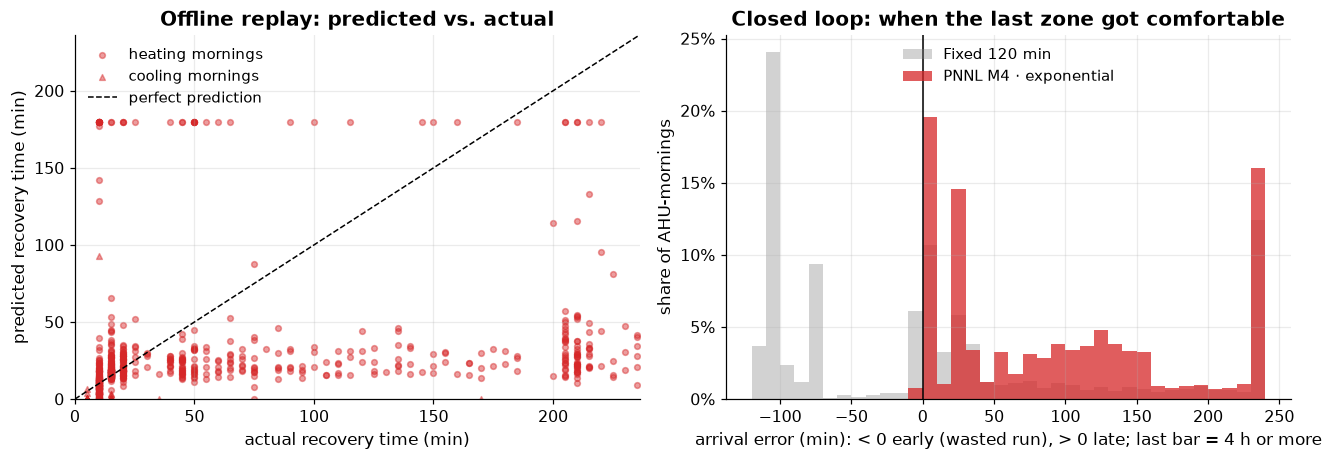

In [12]:
key = "pnnl_m4_exponential"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** the biggest energy savings of any algorithm, and the best simulator reward among the learners, because it
starts late. **Weaknesses:** that's mostly lateness, not intelligence: it is late on far more mornings than a fixed schedule,
with the worst comfort of the whole field and the worst single-scenario result (see the leaderboard).

### PNNL's deployed version: median of the four
PNNL's field agent doesn't pick one model: it runs all four and uses the **median** prediction, with a separate set trained
only on post-weekend days (the paper's "Monday problem"). We benchmark that too, as `PNNL deployed (median of M1-M4)`.

<a id="v7"></a>
## 7. Our G36 recovery learner (NeurIPS v7)

### How it works
**Intuition.** This is the start logic inside our NeurIPS 2026 competition controller ("v7"). Instead of learning one number
per morning, it **learns the warm-up speed every 5 minutes while the warm-up is running**, from the average of a fixed
random 20 % of the zones on each air handler. Then it starts early enough for that speed, plus a safety margin.

$$\widehat{t} = 1.25\,\frac{T_{sp} - \bar T_{\text{sample}}}{R} + 15\ \text{min}, \qquad 5 \le \widehat{t} \le 120$$

$$R \leftarrow 0.5\,R + 0.5\,\frac{\Delta T_{\text{last 5 min}}}{5\ \text{min}} \quad\text{(every 5 minutes during warm-up)}$$

* $R$ starts at 0.1 °F/min (6 °F/h) for heating and for cooling.
* If $R \le 0$ (the zone isn't warming up at all), it starts at the 120-minute cap.
* The full v7 controller also predicts occupancy with small decision trees and runs the whole G36 sequence; here we only
  copy its **start rule**.

**Inputs:** zone temperatures (a 20 % sample), occupied setpoints. **Fitting:** a fast EMA ($\alpha = 0.5$) on every
5-minute step of every warm-up. **Worked example.** $R = 0.1$ °F/min, sample 5 °F below setpoint:
$1.25 \cdot 5/0.1 + 15 = 77.5$ minutes.

**When it works / when it fails.** It reacts within minutes to a slow morning and has a safety factor built in, so it
almost never starts absurdly late. But it plans for the *average* zone, not the coldest one, so the coldest zone is more
often still cold at occupancy. The 120-minute cap also limits it in very cold climates.

In [13]:
class G36RecoveryLearner:
    """Start rule of the NeurIPS v7 G36 controller (per-5-minute EMA of the recovery rate, x1.25 + 15 min)."""
    name = "v7"
    def __init__(self, prior=0.1, alpha=0.5, safety=1.25, buffer=15.0, lo=5.0, hi=120.0):
        self.R, self.a, self.safety, self.buffer, self.lo, self.hi = {"heat": prior, "cool": prior}, alpha, safety, buffer, lo, hi
    def predict(self, mode, temp, target, oat, post_weekend=False):
        d = deficit(mode, temp, target)
        if d <= 0: return 0.0
        if self.R[mode] <= 0: return self.hi                      # not recovering -> start at the cap
        return float(np.clip(self.safety * d / self.R[mode] + self.buffer, self.lo, self.hi))
    def update(self, ev):
        sign = 1 if ev["mode"] == "heat" else -1
        tr = ev["traj"]
        for (t0, x0), (t1, x1) in zip(tr[:-1], tr[1:]):        # every 5-minute step of the warm-up
            self.R[ev["mode"]] = (1 - self.a) * self.R[ev["mode"]] + self.a * sign * (x1 - x0) / (t1 - t0)

print("worked example:", G36RecoveryLearner().predict("heat", 65, 70, 30), "min")
REPLAY["v7"] = replay(G36RecoveryLearner)

worked example: 77.5 min


### Evaluation
The offline replay applies the v7 rule to the same recorded coldest-zone recoveries as the other models (the real controller
uses a 20 % zone average, so its closed-loop behaviour can differ a bit). The closed-loop numbers are the real v7 controller.

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
G36 recovery learner (v7),"1,033",44.5,19.4,15.8,40.9


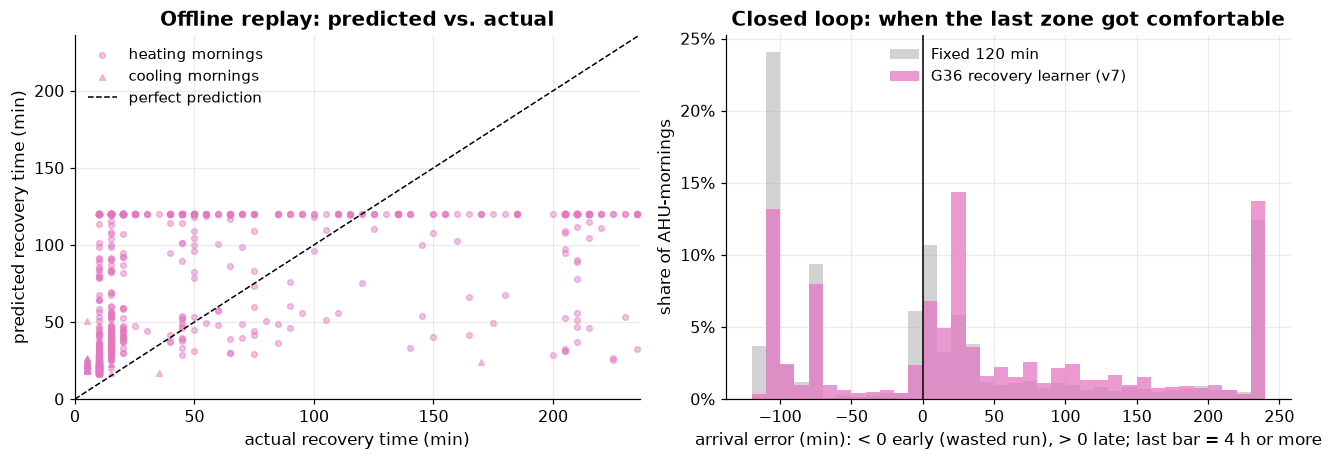

In [14]:
key = "v7"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

**Strengths:** the **best competition score of all the learned algorithms**, and the smallest worst-case score loss (see the
leaderboard). It learns fast and its safety margin keeps it from ever starting very late. **Weaknesses:** it targets the
average zone, so the coldest zone is late more often than with the other learners, and it doesn't beat a fixed schedule on
the energy-vs-comfort trade-off.

<a id="m0"></a>
## 8. The linear-rate EMA: the simplest learner

### How it works
**Intuition.** Forget curves and weather ratios. Track one number per mode, the zone's **recovery rate** in °F per minute,
and update it a little every morning. Predicted time is just the gap divided by the rate.

$$\widehat{t} = \frac{T_{sp} - T_{z,0}}{R}, \qquad R \leftarrow R + w\left(\frac{\Delta T_0}{t_{act}} - R\right), \quad w = 0.2$$

**How it differs from the others**
* **One number, one update a day.** No windows, no quadratic term, no outdoor-air ratio that can blow up.
* **It learns from the whole warm-up** (gap ÷ minutes it took), so the slow start-up is baked into the rate.
* **A slow EMA ($w=0.2$)** smooths out noisy days but still follows the seasons within about a week.
* Unlike v7 it learns once per morning, from the **coldest** zone, with no built-in safety factor.

**Worked example.** $R = 0.1$ °F/min and a 5 °F gap: 50 minutes. Today it actually took 40 min (rate 0.125), so
$R \leftarrow 0.1 + 0.2(0.125-0.1) = 0.105$ °F/min.

**When it works / when it fails.** Works well wherever recovery speed is fairly steady (most mornings in most climates).
It has no weather term, so a sudden cold snap or a cold-soaked Monday can make it late; a fixed safety margin or a
post-weekend factor is the natural add-on.

In [15]:
class LinearRateEMA:
    name = "m0_linear_ema"
    def __init__(self, rate=0.1, w=0.2, min_rate=0.005): self.R, self.w, self.min = {"heat": rate, "cool": rate}, w, min_rate
    def predict(self, mode, temp, target, oat, post_weekend=False):
        return deficit(mode, temp, target) / max(self.min, self.R[mode])
    def update(self, ev):
        d0 = deficit(ev["mode"], ev["start"], ev["target"])
        if ev["t"] and d0 > 0:
            self.R[ev["mode"]] = max(self.min, self.R[ev["mode"]] + self.w * (d0 / ev["t"] - self.R[ev["mode"]]))

m = LinearRateEMA(); print("worked example:", m.predict("heat", 65, 70, 30), "min ->", end=" ")
m.update(dict(mode="heat", start=65, target=70, t=40)); print(f"rate {m.R['heat']:.3f} °F/min")
REPLAY["m0_linear_ema"] = replay(LinearRateEMA)

worked example: 50.0 min -> rate 0.105 °F/min


### Evaluation

,recoveries,MAE (min),bias (min),late starts %,within ±15 min %
Linear-rate EMA,"1,033",28.9,-14.1,25.8,62.1


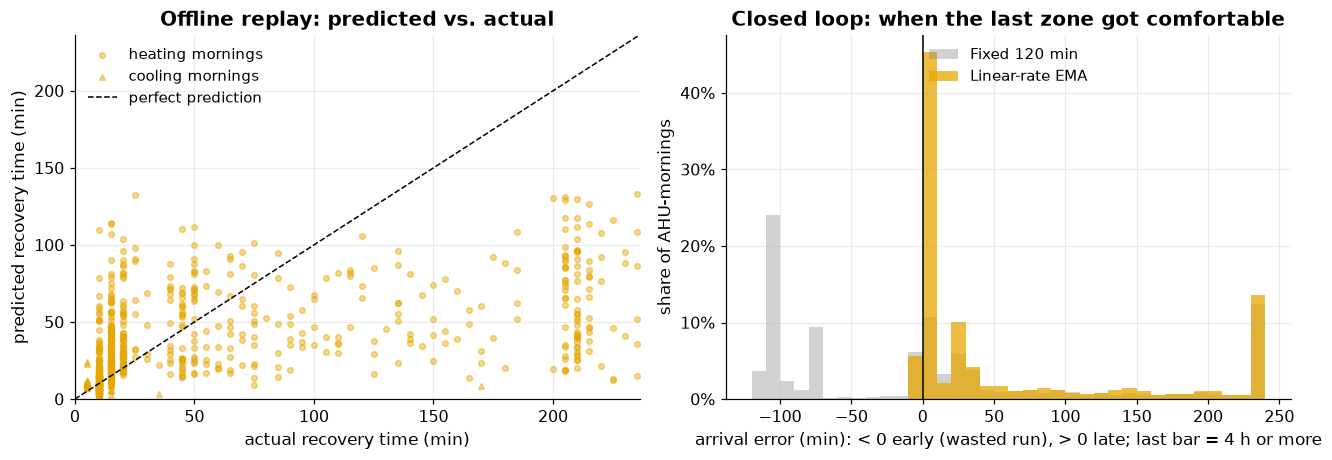

In [16]:
key = "m0_linear_ema"
show_replay(key)
evaluation_plots(key, REPLAY[key]); climate_table(key)

### Head-to-head: PNNL models vs. v7 vs. EMA

The fair comparison is the **energy-vs-comfort trade-off**, not raw savings. In each scenario the three fixed schedules
(60, 120, 180 min) define the curve any schedule can reach. The chart puts every algorithm on that map: up = more energy
saved, left = better comfort. Points **above the grey schedule curve** beat every fixed schedule.

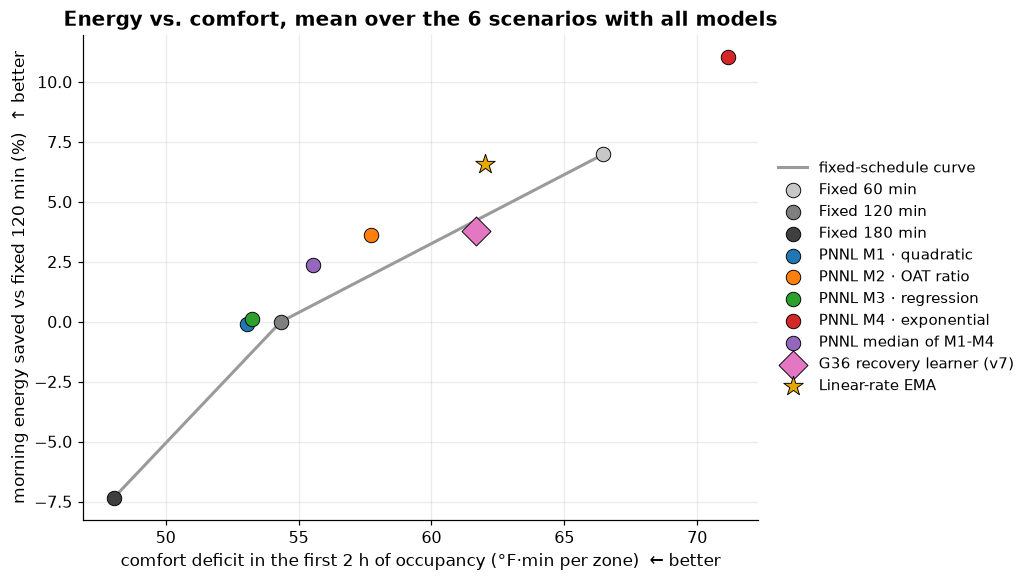

,competition score vs fixed 120 % (lower = better),savings beyond schedule % (mean),… worst scenario,reward regret (mean),late % (1 °F tol.),unmet (°F·min/zone)
start,,,,,,
PNNL M1 · quadratic,0.61,0.29,-1.09,-0.18,45.92,53.05
PNNL M2 · OAT ratio,0.86,0.49,-0.58,-0.15,47.44,57.71
PNNL M3 · regression,0.54,0.33,-1.31,-0.17,43.69,53.24
PNNL M4 · exponential,1.89,0.28,-4.02,-0.04,52.17,71.14
PNNL median of M1-M4,0.72,0.67,-0.55,-0.15,46.37,55.56
G36 recovery learner (v7),0.79,-0.87,-5.17,-0.06,47.29,61.68
Linear-rate EMA,1.32,0.73,-0.78,-0.09,49.74,62.03
Fixed 120 min,0.00,0.00,0.00,-0.08,36.34,54.34


In [17]:
# Per-scenario table used by the leaderboard as well.
P = score(["scenario", "start"]).reset_index()
_S = RUN.pivot_table(index="scenario", columns="start", values="score")
P["comp"] = [100 * (_S.loc[r.scenario, r.start] / _S.loc[r.scenario, "fixed_120"] - 1) for r in P.itertuples()]

def beyond_schedule(g):
    """Energy % saved beyond the fixed-schedule curve at equal comfort, per scenario."""
    anc = g[g.start.isin(["fixed_60", "fixed_120", "fixed_180"])].sort_values("unmet")
    if len(anc) < 2: return pd.Series(np.nan, index=g.index)
    u, e = anc.unmet.to_numpy(), anc.saved_pct.to_numpy()
    def sched(x):
        i = 0 if x <= u[0] else (len(u) - 2 if x >= u[-1] else int(np.searchsorted(u, x) - 1))
        return e[i] + (e[i + 1] - e[i]) * (x - u[i]) / (u[i + 1] - u[i])
    return g.saved_pct - g.unmet.map(sched)

P["beyond"] = P.groupby("scenario", group_keys=False).apply(beyond_schedule)
P["regret"] = P.reward_gain - P.groupby("scenario").reward_gain.transform("max")

# Trade-off map on the 6 scenarios where every PNNL model and all three schedules were run.
common = P[P.start == "pnnl_m1_quadratic"].scenario
sub = P[P.scenario.isin(common)]
M = sub.groupby("start")[["unmet", "saved_pct"]].mean()
fig, ax = plt.subplots(figsize=(9.5, 5.4))
sch = M.loc[["fixed_180", "fixed_120", "fixed_60"]]
ax.plot(sch.unmet, sch.saved_pct, "-", color="#9a9a9a", lw=2, zorder=1, label="fixed-schedule curve")
for k in ["fixed_60", "fixed_120", "fixed_180", "pnnl_m1_quadratic", "pnnl_m2_oat_ratio", "pnnl_m3_regression",
          "pnnl_m4_exponential", "pnnl_deployed_median_split", "v7", "m0_linear_ema"]:
    x, y = M.loc[k]
    big = k in ("m0_linear_ema", "v7")
    ax.scatter(x, y, s=180 if big else 90, color=COLORS[k], edgecolor="k", lw=0.6, zorder=3,
               marker=("*" if k == "m0_linear_ema" else "D") if big else "o", label=NAMES[k])
ax.set_xlabel("comfort deficit in the first 2 h of occupancy (°F·min per zone)  ← better")
ax.set_ylabel("morning energy saved vs fixed 120 min (%)  ↑ better")
ax.set_title(f"Energy vs. comfort, mean over the {len(common)} scenarios with all models")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.tight_layout(); plt.show()

H = sub.groupby("start").agg(comp=("comp", "mean"), beyond=("beyond", "mean"), worst=("beyond", "min"),
                             regret=("regret", "mean"), late=("late_pct", "mean"), unmet=("unmet", "mean"))
H = H.loc[CONTENDERS + ["fixed_120"]]
display(H.rename(index=NAMES, columns={"comp": "competition score vs fixed 120 % (lower = better)",
        "beyond": "savings beyond schedule % (mean)", "worst": "… worst scenario",
        "regret": "reward regret (mean)", "late": "late % (1 °F tol.)", "unmet": "unmet (°F·min/zone)"})
        .pipe(lambda t: t.style.format(F(t, "{:.2f}"))).set_caption(f"Head-to-head on the {len(common)} common scenarios"))

**What this shows (6 scenarios where every model ran):**
* **Energy vs. comfort:** the EMA (+0.73 %) and the PNNL median (+0.67 %) land furthest above the fixed-schedule curve.
  v7 sits below it (−0.87 %): it saves energy mostly by accepting more comfort misses.
* **Competition score:** PNNL M3 and M1 come out best here (+0.54 %, +0.61 %), then the median (+0.72 %) and v7 (+0.79 %).
  Over all 22 scenarios, where M1-M3 weren't run, v7 has the best score of the learners (see the leaderboard).
* **Morning reward:** PNNL M4 is best (−0.04) because it starts very late; it also has the worst comfort.
* **Comfort:** none of the learners matches a fixed 2-hour start; M3 comes closest on late mornings.

<a id="stop"></a>
## 9. Optimal stop: first-order coast-down

### How it works
**Intuition.** Near the end of the day, ask: *if I switch this AHU off now, will every zone stay comfortable until the
building empties?* If yes, stop. To answer it, learn how each zone drifts while the fan is off.

The zone is modelled as one thermal resistance and one capacitance (1R1C):

$$\frac{dT}{dt} = a\,(T_o - T) + b + c\cdot\text{occupied}$$

$a$ is the envelope coupling to outdoors, $b$ a constant gain/loss and $c$ the extra heat from people and plugs. With OAT
held at its current value the exact solution is an exponential approach to $T_\infty = T_o + (b+c)/a$:

$$T(t) = T_\infty + (T_0 - T_\infty)\,e^{-a t}$$

**Inputs:** zone temperature, OAT, occupancy flag. **Fitting:** recursive least squares with slow forgetting
($\lambda = 0.999$) on every 5-minute interval the AHU is off (nights, weekends, coasts). The projection gets an uncertainty
cone ($\pm 2$ robust sigma of past residuals + 0.15 °F/h model error). **Decision:** stop if the whole cone stays inside the
band minus a guard (0.2 °F here) until the end of occupancy, at most 2 h early; restart if any zone comes within 0.27 °F of
a band edge.

**When it works / when it fails.** Works in shoulder seasons and well-insulated buildings that drift slowly. It (correctly)
almost never stops in extreme cold or heat, and it needs about two hours of off-time history before it acts at all.

learned a, b, c = [0.085 0.634 0.897]  true = (0.08, 0.6, 0.9)


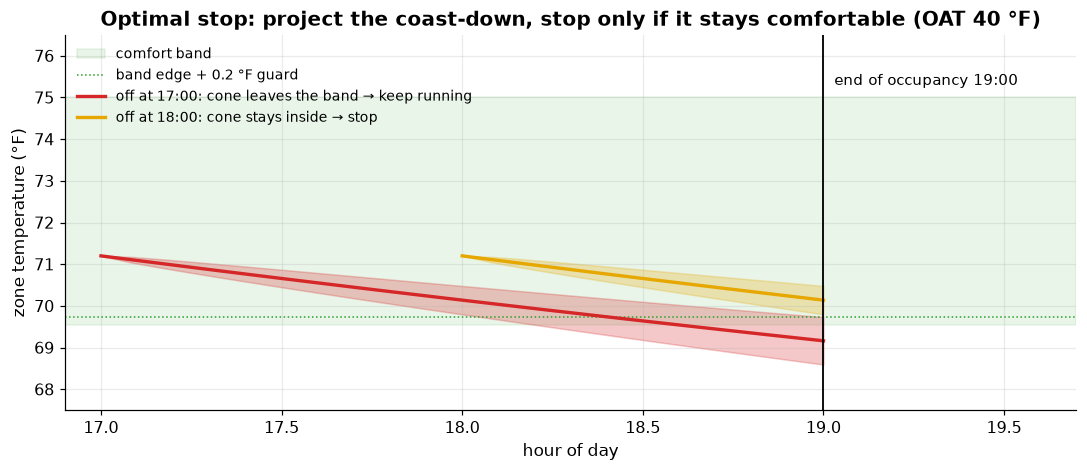

stop at 17:00 for 2 h? False | stop for the last 60 min? True


In [18]:
class FirstOrderCoast:
    """1R1C coast model learned by recursive least squares on AHU-off intervals."""
    def __init__(self, lam=0.999, k=2.0, struct=0.15):
        self.th, self.P, self.lam, self.k, self.struct, self.res = np.array([0.05, 0.0, 0.3]), np.diag([0.01, 1.0, 1.0]), lam, k, struct, []
    def update(self, t0, t1, oat, minutes, occupied):
        x = np.array([oat - t0, 1.0, float(occupied)]); y = (t1 - t0) / (minutes / 60)   # observed drift, °F/h
        Px = self.P @ x; K = Px / (self.lam + x @ Px); err = y - x @ self.th
        self.th = self.th + K * err; self.P = (self.P - np.outer(K, Px)) / self.lam; self.res.append(err)
    def bounds(self, temp, oat, minutes, occupied=True):
        a, b, c = self.th; a = max(a, 1e-4); h = minutes / 60
        t_inf = oat + (b + (c if occupied else 0.0)) / a
        mid = t_inf + (temp - t_inf) * math.exp(-a * h)
        r = np.asarray(self.res[-500:]); sigma = 1.4826 * np.median(np.abs(r - np.median(r))) if len(r) >= 12 else 1.0
        unc = (self.k * sigma / math.sqrt(max(1.0, minutes / 5)) + self.struct) * h
        return mid - unc, mid + unc

def should_stop(model, temp, oat, minutes_left, heat_sp=69.53, cool_sp=75.0, guard=0.2):
    lo, hi = model.bounds(temp, oat, minutes_left)
    return lo >= heat_sp + guard and hi <= cool_sp - guard

# Demo: learn from synthetic off-hours drift of a zone with a = 0.08 /h, b = 0.6 °F/h, c = 0.9 °F/h, then project.
rng = np.random.default_rng(7); true = (0.08, 0.6, 0.9); m = FirstOrderCoast(); T = 70.0
for i in range(600):                     # ~2 days of 5-minute off intervals
    oat, occ = 45 + 10 * math.sin(i / 288 * 2 * math.pi), (i % 288) > 200
    dT = (true[0] * (oat - T) + true[1] + true[2] * occ) * (5 / 60) + rng.normal(0, 0.03)
    m.update(T, T + dT, oat, 5, occ); T = float(np.clip(T + dT, 62, 78))
print("learned a, b, c =", np.round(m.th, 3), " true =", true)

fig, ax = plt.subplots(figsize=(10, 4.4)); T0, oat = 71.2, 40.0
ax.axhspan(69.53, 75.0, color="#2ca02c", alpha=0.10, label="comfort band")
ax.axhline(69.53 + 0.2, color="#2ca02c", ls=":", lw=1, label="band edge + 0.2 °F guard")
for t_off, col, lab in [(17.0, "#d62728", "off at 17:00: cone leaves the band → keep running"),
                        (18.0, STOP_COLORS["first_order_coast"], "off at 18:00: cone stays inside → stop")]:
    t = np.arange(0, (19 - t_off) * 60 + 1, 5)
    lh = np.array([m.bounds(T0, oat, max(x, 1e-6)) for x in t])
    ax.fill_between(t_off + t / 60, lh[:, 0], lh[:, 1], color=col, alpha=0.25)
    ax.plot(t_off + t / 60, lh.mean(axis=1), color=col, lw=2.2, label=lab)
ax.axvline(19, color="k", lw=1.2); ax.text(19.03, 75.3, "end of occupancy 19:00", fontsize=9.5)
ax.set_xlabel("hour of day"); ax.set_ylabel("zone temperature (°F)"); ax.set_ylim(67.5, 76.5); ax.set_xlim(16.9, 19.7)
ax.set_title("Optimal stop: project the coast-down, stop only if it stays comfortable (OAT 40 °F)")
ax.legend(loc="upper left", fontsize=9); plt.tight_layout(); plt.show()
print("stop at 17:00 for 2 h?", should_stop(m, T0, oat, 120), "| stop for the last 60 min?", should_stop(m, T0, oat, 60))

### Evaluation

In the main runs every algorithm used a 0.9 °F stop guard, the same as the NeurIPS v6 controller. With that guard the stop
algorithms **almost never fired** (under 0.4 % of AHU-days): the G36 sequence holds zones within about 0.7 °F of the band edge
in the late afternoon.
So we ran a dedicated stop experiment: the same fixed 120-minute start in every run, a 0.2 °F guard, four stop algorithms,
one building in four climates (Atlanta, Denver, Minneapolis, Phoenix), all 30 days scored.

,AHU-days,days stopped early %,early-stop min (mean),restarts/day,unmet last 3 h (°F·min/zone),evening energy saved %,reward gain
stop,,,,,,,
First-order coast (ours),336,5.65,0.39,0.43,12.56,3.01,-0.009
Constant drift 0.35 °F/h,336,2.08,0.12,0.69,17.58,5.71,-0.050
G36 stop (v6/v7 controller),336,0.60,0.04,0.00,11.68,-0.05,+0.004
No early stop,336,0.00,0.00,0.00,11.82,0.00,+0.000


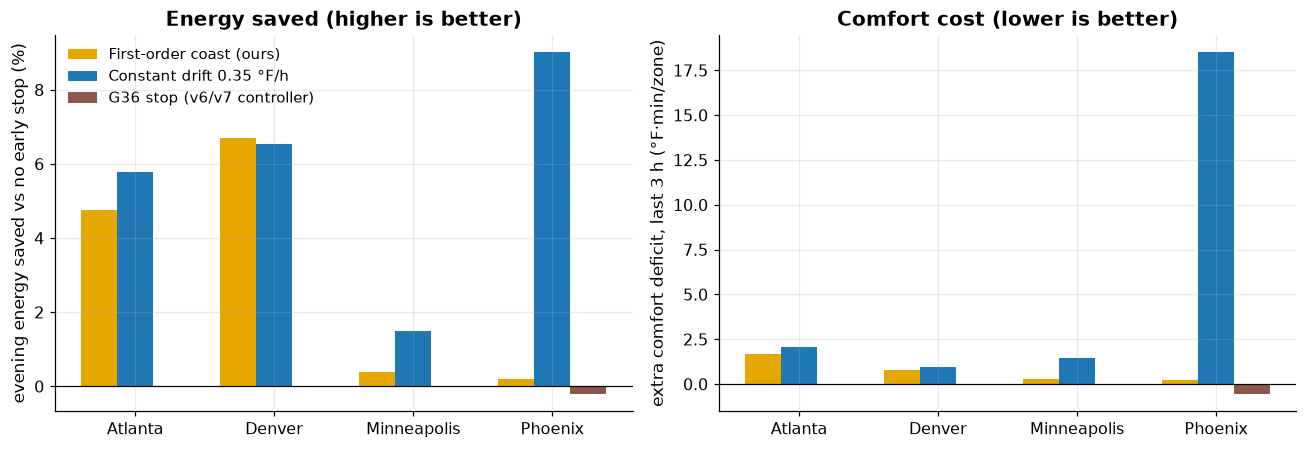

In [19]:
g = SD.groupby(["scenario", "date", "stop"], as_index=False)[["evening_energy", "evening_reward"]].mean()
b0 = g[g.stop == "no_early_stop"].rename(columns={"evening_energy": "e0", "evening_reward": "r0"}).drop(columns="stop")
g = g.merge(b0, on=["scenario", "date"]); g["saved"] = 100 * (g.e0 - g.evening_energy) / g.e0; g["dr"] = g.evening_reward - g.r0
g["city"] = g.scenario.str.split("/").str[1].str.split("_").str[0]
SA["stop_unmet_f"] = SA.stop_unmet * K2F
def stop_table(by):
    s = SA.groupby(by).agg(days=("stop_lead", "size"), stopped=("stop_lead", lambda x: 100 * (x > 0).mean()),
                           early_min=("stop_lead", "mean"), restarts=("restarts", "mean"), unmet=("stop_unmet_f", "mean"))
    return s.join(g.groupby(by).agg(saved=("saved", "mean"), reward=("dr", "mean")))
ST = stop_table(["stop"]).loc[["first_order_coast", "vavrl_const_drift", "v6", "no_early_stop"]]
display(ST.rename(index=STOP_NAMES, columns={"days": "AHU-days", "stopped": "days stopped early %", "early_min": "early-stop min (mean)",
        "restarts": "restarts/day", "unmet": "unmet last 3 h (°F·min/zone)", "saved": "evening energy saved %", "reward": "reward gain"})
        .pipe(lambda t: t.style.format(F(t, "{:.2f}", **{"AHU-days": "{:,.0f}", "reward gain": "{:+.3f}"}))).set_caption("Optimal stop, all four climates"))

SC = stop_table(["stop", "city"]).reset_index()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
cities = sorted(SC.city.unique()); x = np.arange(len(cities)); wd = 0.26
for i, k in enumerate(["first_order_coast", "vavrl_const_drift", "v6"]):
    s = SC[SC.stop == k].set_index("city").reindex(cities)
    base = SC[SC.stop == "no_early_stop"].set_index("city").reindex(cities)
    a1.bar(x + (i - 1) * wd, s.saved, wd, color=STOP_COLORS[k], label=STOP_NAMES[k])
    a2.bar(x + (i - 1) * wd, s.unmet - base.unmet, wd, color=STOP_COLORS[k], label=STOP_NAMES[k])
for ax, yl, tt in [(a1, "evening energy saved vs no early stop (%)", "Energy saved (higher is better)"),
                   (a2, "extra comfort deficit, last 3 h (°F·min/zone)", "Comfort cost (lower is better)")]:
    ax.set_xticks(x); ax.set_xticklabels([c.title() for c in cities]); ax.set_ylabel(yl); ax.set_title(tt); ax.axhline(0, color="k", lw=0.8)
a1.legend(); plt.tight_layout(); plt.show()

**Verdict.** The **first-order coast** is the best stop algorithm on the worst case. It stops early on about 6 % of
AHU-days and saves **3.0 % of evening energy** for **+0.7 °F·min/zone** of extra comfort deficit, with a reward change of only
−0.009. The constant-drift rule (0.35 °F/h, a common rule of thumb) saves more energy (5.7 %), but in Phoenix it turns the
AHU off on hot afternoons and the comfort deficit jumps by about 18 °F·min/zone (reward −0.05). The G36 stop used by our v6/v7
controller almost never stops. The opportunity is real but small: G36 already runs these buildings tightly in the evening.

<a id="board"></a>
## 10. Leaderboard: who wins what

Only the seven contenders, with the fixed 120-minute start as the reference row. PNNL M1-M3 were run on 6 of the 22
scenarios (marked), so their worst cases aren't directly comparable. "Savings beyond schedule" needs the fixed 60/120/180
runs, which exist for 12 scenarios.

In [20]:
L = P[P.start.isin(CONTENDERS + ["fixed_120"])].groupby("start").agg(
    scenarios=("scenario", "nunique"), comp=("comp", "mean"), comp_worst=("comp", "max"),
    beyond=("beyond", "mean"), beyond_worst=("beyond", "min"), regret=("regret", "mean"), regret_worst=("regret", "min"))
L = L.join(score(["start"])[["late_pct", "unmet", "saved_pct"]]).sort_values("comp")
LB = L.rename(index=NAMES, columns={"comp": "competition score vs fixed 120 %", "comp_worst": "… worst scenario",
              "beyond": "savings beyond schedule %", "beyond_worst": "… worst scenario ",
              "regret": "morning reward regret", "regret_worst": "… worst scenario  ",
              "late_pct": "late %", "unmet": "unmet °F·min/zone", "saved_pct": "morning energy saved %"})
def hl(row):
    return ["background-color: #fde7f3; font-weight: bold" if row.name == NAMES["v7"] else
            ("background-color: #fff3c4" if row.name == NAMES["m0_linear_ema"] else "") for _ in row]
display(LB.style.format(F(LB, "{:.2f}", scenarios="{:.0f}", **{"morning reward regret": "{:.3f}", "… worst scenario  ": "{:.3f}"}), na_rep="–")
        .apply(hl, axis=1).set_caption("Start leaderboard, sorted by competition score (lower is better)"))

# Who wins each metric (algorithms run on all 22 scenarios only, so the comparison is fair)
full = [k for k in CONTENDERS if L.loc[k, "scenarios"] == 22]
pick = lambda col, best: NAMES[(L.loc[full, col].idxmin() if best == "min" else L.loc[full, col].idxmax())]
W = pd.DataFrame([
    ("Competition score (whole month)", pick("comp", "min"), "lower % vs fixed 120"),
    ("Competition score, worst scenario", pick("comp_worst", "min"), "smallest worst-case loss"),
    ("Energy at equal comfort (savings beyond schedule)", pick("beyond", "max"), "higher"),
    ("Morning simulator reward", pick("regret", "max"), "closest to the best run"),
    ("Comfort: fewest late mornings", pick("late_pct", "min"), "lower late %"),
    ("Comfort: smallest deficit", pick("unmet", "min"), "lower °F·min/zone"),
    ("Most morning energy saved", pick("saved_pct", "max"), "higher (often by being late)"),
], columns=["metric", "winner (of the algorithms run on all 22 scenarios)", "what 'best' means"])
display(W.style.hide(axis="index").set_caption("Winner per metric"))

,scenarios,competition score vs fixed 120 %,… worst scenario,savings beyond schedule %,… worst scenario,morning reward regret,… worst scenario,late %,unmet °F·min/zone,morning energy saved %
start,,,,,,,,,,
Fixed 120 min,22,0.00,0.00,0.00,-0.00,-0.073,-0.260,33.90,49.03,0.00
PNNL M3 · regression,6,0.54,1.53,0.33,-1.31,-0.167,-0.520,45.95,51.44,0.13
PNNL M1 · quadratic,6,0.61,1.41,0.29,-1.09,-0.180,-0.520,47.30,51.26,-0.10
G36 recovery learner (v7),22,0.74,2.54,-0.83,-6.04,-0.054,-0.212,46.85,55.89,4.19
PNNL M2 · OAT ratio,6,0.86,1.66,0.49,-0.58,-0.147,-0.501,47.80,56.37,3.64
PNNL median of M1-M4,22,0.88,4.85,1.76,-0.61,-0.110,-0.470,40.00,50.63,3.70
Linear-rate EMA,22,0.96,4.90,1.60,-0.78,-0.056,-0.259,42.65,55.55,8.54
PNNL M4 · exponential,22,1.93,5.85,-0.40,-9.48,-0.025,-0.084,45.15,64.50,13.82


metric,winner (of the algorithms run on all 22 scenarios),what 'best' means
Competition score (whole month),G36 recovery learner (v7),lower % vs fixed 120
"Competition score, worst scenario",G36 recovery learner (v7),smallest worst-case loss
Energy at equal comfort (savings beyond schedule),PNNL median of M1-M4,higher
Morning simulator reward,PNNL M4 · exponential,closest to the best run
Comfort: fewest late mornings,PNNL median of M1-M4,lower late %
Comfort: smallest deficit,PNNL median of M1-M4,lower °F·min/zone
Most morning energy saved,PNNL M4 · exponential,higher (often by being late)


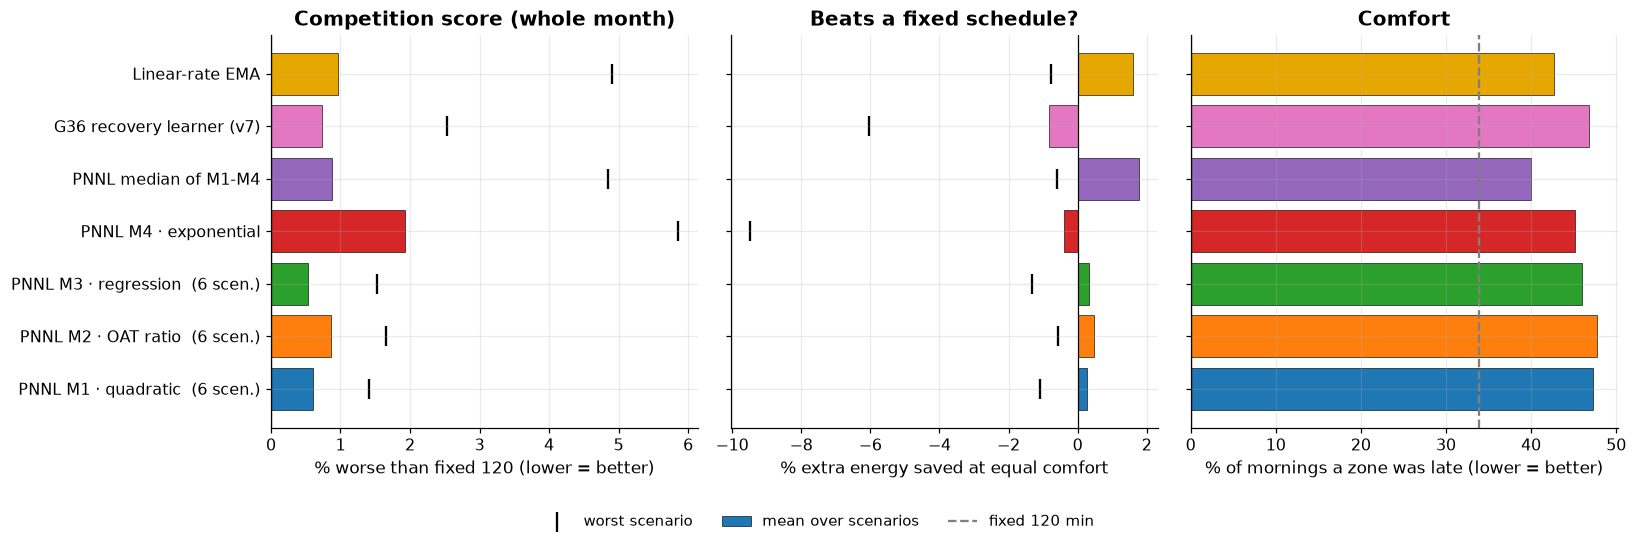

In [21]:
keys = [k for k in CONTENDERS]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
y = np.arange(len(keys))
for ax, col, worst, xl, tt in [
        (axes[0], "comp", "comp_worst", "% worse than fixed 120 (lower = better)", "Competition score (whole month)"),
        (axes[1], "beyond", "beyond_worst", "% extra energy saved at equal comfort", "Beats a fixed schedule?"),
        (axes[2], "late_pct", None, "% of mornings a zone was late (lower = better)", "Comfort")]:
    ax.barh(y, L.loc[keys, col], color=[COLORS[k] for k in keys], edgecolor="k", lw=0.4, label="mean over scenarios")
    if worst: ax.scatter(L.loc[keys, worst], y, marker="|", s=160, color="k", label="worst scenario")
    if col == "late_pct": ax.axvline(L.loc["fixed_120", "late_pct"], color=COLORS["fixed_120"], ls="--", label="fixed 120 min")
    ax.axvline(0, color="k", lw=0.8); ax.set_xlabel(xl); ax.set_title(tt)
axes[0].set_yticks(y); axes[0].set_yticklabels([NAMES[k] + ("  (6 scen.)" if L.loc[k, "scenarios"] < 10 else "") for k in keys])
h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = axes[2].get_legend_handles_labels()
fig.legend(h1 + h2[:1], l1 + l2[:1], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

### The Monday problem

The PNNL paper found all four models did poorly on Mondays: after a weekend setback the building is cold-soaked and
recovers slower than any weekday taught the model. Same here: lateness on the first morning after a weekend vs. other days.

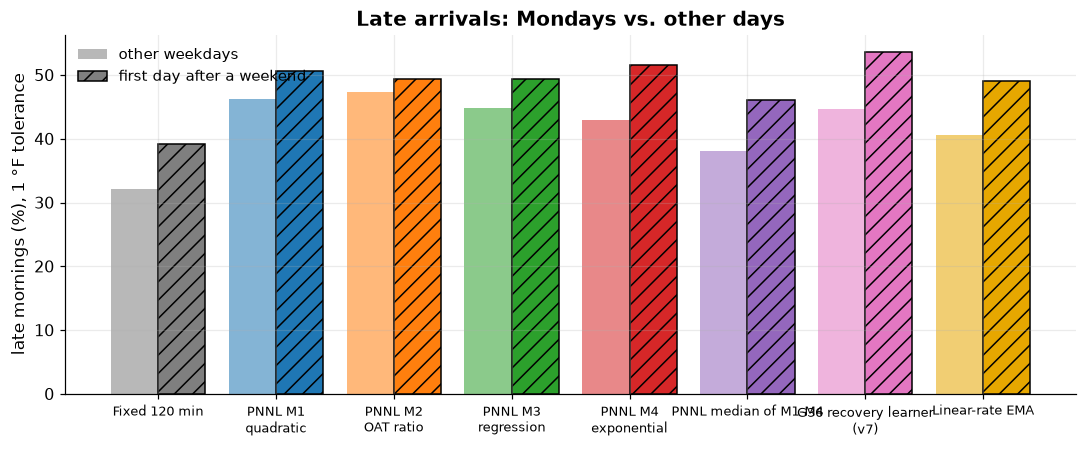

In [22]:
K = ["fixed_120"] + CONTENDERS
MW = A[A.start.isin(K)].groupby(["start", "post_weekend"]).late_tol.apply(lambda x: 100 * (x > 0).mean()).unstack()
fig, ax = plt.subplots(figsize=(10, 4.2)); x = np.arange(len(K))
ax.bar(x - 0.2, MW.loc[K, False], 0.4, color=[COLORS[k] for k in K], alpha=0.55, label="other weekdays")
ax.bar(x + 0.2, MW.loc[K, True], 0.4, color=[COLORS[k] for k in K], edgecolor="k", hatch="//", label="first day after a weekend")
ax.set_xticks(x); ax.set_xticklabels([NAMES[k].replace(" · ", "\n").replace(" (", "\n(") for k in K], fontsize=8.5)
ax.set_ylabel("late mornings (%), 1 °F tolerance"); ax.set_title("Late arrivals: Mondays vs. other days"); ax.legend()
plt.tight_layout(); plt.show()

<div style="border-left: 6px solid #e377c2; background: #fdf2f8; padding: 12px 18px; border-radius: 4px;">

### Recommendation
* **For the NeurIPS / Kaggle competition: keep the G36 recovery learner (v7).** It has the best competition score of the
  learned algorithms over all 22 scenarios (+0.74 % vs a fixed 2 h start) and by far the smallest worst case (+2.5 % vs
  +4.9 to +5.9 % for the others). Its margin (×1.25 + 15 min) gives the fewest late starts in the replay.
* **For a real building controller, especially one with only basic math: the linear-rate EMA.** The best predictor, nearly
  the best energy-at-equal-comfort result, and the simplest code (see the deployability section).
* **If comfort matters most and you can run four models: the PNNL median of four.** Fewest late mornings and the best
  energy-at-equal-comfort score; avoid PNNL Model 4 on its own.
* **Optimal stop: the first-order coast model** with a tight guard (0.2 °F) and a restart rule.
* **Mondays need help.** Every algorithm is late more often on the first day after a weekend. Keep a separate post-weekend
  rate, or add 15-30 min on those days.
</div>

<a id="deploy"></a>
## 11. Deployability: how hard is each one to run on a real controller?

If you want to run optimal start on an IoT gateway or inside a building-automation script hook (Python or plain
JavaScript), simple matters as much as accurate. The table below is derived from the implementations in this notebook:

* **n** = number of stored days in a model's rolling window (PNNL uses **W = 8**), **T** = 5-minute samples in one
  morning's warm-up (typically 2 to 40), **R** = stored residuals in the stop model (capped at 500 here).
* "Per-day update" is the work done once per morning after the warm-up; "predict" is the work each time you ask
  "how long do I need?" (usually every 5 minutes before occupancy).

In [23]:
import timeit, tracemalloc, pickle, statistics

class PNNLMedian:
    """PNNL's deployed rule: median of the four models (no history counts as the 180-min maximum)."""
    name = "pnnl_deployed_median_split"
    def __init__(self): self.ms = [PNNLModel1(), PNNLModel2(), PNNLModel3(), PNNLModel4()]
    def predict(self, mode, temp, target, oat, post_weekend=False):
        ps = [m.predict(mode, temp, target, oat) for m in self.ms]
        return statistics.median([180.0 if p is None else p for p in ps])
    def update(self, ev):
        for m in self.ms: m.update(ev)

IMPL = {"pnnl_m1_quadratic": PNNLModel1, "pnnl_m2_oat_ratio": PNNLModel2, "pnnl_m3_regression": PNNLModel3,
        "pnnl_m4_exponential": PNNLModel4, "pnnl_deployed_median_split": PNNLMedian,
        "v7": G36RecoveryLearner, "m0_linear_ema": LinearRateEMA}

# One AHU's recorded mornings, used for every model.
g = EV[EV.minutes_to_target.notna()].groupby(["scenario", "ahu"]).filter(lambda x: len(x) >= 15)
g = g[(g.scenario == g.scenario.iloc[0]) & (g.ahu == g.ahu.iloc[0])]
evs = [dict(mode=e.mode, start=e.start_temp_f, target=e.target_f, oat=e.oat_f, oat_mean=e.oat_mean_f,
            t=e.minutes_to_target, traj=TRAJ[e.event], arrival_error=0.0) for e in g.itertuples()]

def bench(cls):
    m = cls()
    for ev in evs: m.update(ev)                                   # a trained model (full windows)
    ev = evs[-1]
    t_pred = min(timeit.repeat(lambda: m.predict(ev["mode"], ev["start"], ev["target"], ev["oat"]), number=2000, repeat=5)) / 2000
    t_upd = min(timeit.repeat(lambda: cls().update(ev), number=500, repeat=5)) / 500
    tracemalloc.start(); m2 = cls()
    for e in evs: m2.update(e); m2.predict(e["mode"], e["start"], e["target"], e["oat"])
    peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop()
    return t_pred * 1e6, t_upd * 1e6, len(pickle.dumps(m.__dict__ if not isinstance(m, PNNLMedian) else [x.__dict__ for x in m.ms])), peak / 1024

REPLAY["pnnl_deployed_median_split"] = replay(PNNLMedian)
BENCH = pd.DataFrame({k: bench(c) for k, c in IMPL.items()}, index=["predict (µs)", "per-day update (µs)",
                     "saved state (bytes)", "peak memory while learning (KiB)"]).T

In [24]:
# Facts read off the implementations above. Lines of code = non-blank lines of the class in this notebook, plus the
# shared helpers it needs (PNNL weighted average: 4 lines, first-degree time: 6 lines).
FACTS = pd.DataFrame({
  "m0_linear_ema":       ["O(1)", "O(1)", "O(1): 2 numbers", "running average (closed form)", 2, "zone temp, setpoint", 9],
  "v7":                  ["O(1)", "O(T)", "O(1): 2 numbers", "running average every 5 min", 6, "zone temps (20 % sample), setpoint", 14],
  "pnnl_m2_oat_ratio":   ["O(W)", "O(1)", "O(W): 2·W numbers", "ratio + PNNL weighted average", 3, "zone temp, setpoint, outdoor temp", 17 + 4],
  "pnnl_m1_quadratic":   ["O(W)", "O(T)", "O(W): 2·W numbers", "two-point fit + PNNL average", 2, "zone temp, setpoint", 14 + 10],
  "pnnl_m4_exponential": ["O(W)", "O(T)", "O(W): W numbers", "1-variable least squares over the warm-up", 4, "zone temp, setpoint", 18 + 4],
  "pnnl_m3_regression":  ["O(W)", "O(T)", "O(W): 2·W + 1 numbers", "two-point fit + feedback nudge", 5, "zone temp, setpoint, outdoor temp, yesterday's arrival", 23 + 10],
  "pnnl_deployed_median_split": ["O(W)", "O(T)", "O(W): 7·W + 1 numbers (x2 with PNNL's Monday set)", "all four + median", 14, "zone temp, setpoint, outdoor temp, arrival", 72 + 10 + 8],
}, index=["predict", "per-day update", "memory", "fit method", "tunable parameters", "inputs needed", "lines of code"]).T
FACTS["Python deps"] = "none (pure arithmetic)"
FACTS["plain-JS hook"] = ["trivial", "easy", "easy", "easy", "easy (log/exp only)", "easy", "moderate (4 models)"]
D2 = FACTS.join(BENCH)
# Simple complexity score: lines of code + 5 per tunable parameter + 10 per input beyond zone temp & setpoint
extra_inputs = D2["inputs needed"].str.count(",") - 1
D2["complexity score"] = D2["lines of code"] + 5 * D2["tunable parameters"] + 10 * extra_inputs.clip(lower=0)
D2 = D2.sort_values("complexity score"); D2.insert(0, "rank (1 = simplest)", range(1, len(D2) + 1))
show_cols = ["rank (1 = simplest)", "predict", "per-day update", "memory", "fit method", "tunable parameters", "inputs needed",
             "lines of code", "Python deps", "plain-JS hook", "predict (µs)", "per-day update (µs)", "saved state (bytes)",
             "peak memory while learning (KiB)", "complexity score"]
t = D2[show_cols].rename(index=NAMES)
display(t.style.format(F(t, "{}", **{"predict (µs)": "{:.1f}", "per-day update (µs)": "{:.1f}", "saved state (bytes)": "{:,.0f}",
        "peak memory while learning (KiB)": "{:.1f}", "complexity score": "{:.0f}"})).set_caption("Start algorithms, simplest first"))

,rank (1 = simplest),predict,per-day update,memory,fit method,tunable parameters,inputs needed,lines of code,Python deps,plain-JS hook,predict (µs),per-day update (µs),saved state (bytes),peak memory while learning (KiB),complexity score
Linear-rate EMA,1,O(1),O(1),O(1): 2 numbers,running average (closed form),2,"zone temp, setpoint",9,none (pure arithmetic),trivial,0.1,0.3,84,0.1,19
PNNL M1 · quadratic,2,O(W),O(T),O(W): 2·W numbers,two-point fit + PNNL average,2,"zone temp, setpoint",24,none (pure arithmetic),easy,3.6,1.8,458,1.3,34
PNNL M4 · exponential,3,O(W),O(T),O(W): W numbers,1-variable least squares over the warm-up,4,"zone temp, setpoint",22,none (pure arithmetic),easy (log/exp only),3.6,20.7,151,4.3,42
G36 recovery learner (v7),4,O(1),O(T),O(1): 2 numbers,running average every 5 min,6,"zone temps (20 % sample), setpoint",14,none (pure arithmetic),easy,2.1,5.2,229,1.5,44
PNNL M2 · OAT ratio,5,O(W),O(1),O(W): 2·W numbers,ratio + PNNL weighted average,3,"zone temp, setpoint, outdoor temp",21,none (pure arithmetic),easy,5.1,0.6,217,1.6,46
PNNL M3 · regression,6,O(W),O(T),O(W): 2·W + 1 numbers,two-point fit + feedback nudge,5,"zone temp, setpoint, outdoor temp, yesterday's arrival",33,none (pure arithmetic),easy,3.6,2.2,530,1.3,78
PNNL median of M1-M4,7,O(W),O(T),O(W): 7·W + 1 numbers (x2 with PNNL's Monday set),all four + median,14,"zone temp, setpoint, outdoor temp, arrival",90,none (pure arithmetic),moderate (4 models),17.3,32.4,"1,196",6.8,180


**The stop model** (first-order coast): predict $O(1)$ for the projection plus $O(R \log R)$ for the robust spread of past
residuals (sort for a median; cache it once per day to make predict $O(1)$), update $O(1)$ (a 3-parameter recursive
least-squares step: a 3×3 matrix, 12 numbers of state plus the residual buffer), about 17 lines, 5 tunable parameters,
inputs zone temperature, outdoor temperature and an occupancy flag. It needs no packages: the 3×3 algebra is a few lines
of plain arithmetic in Python or JavaScript (this notebook uses numpy only for convenience).

**What the measurements say.** Every model here takes **microseconds** per call and a few hundred bytes of state: none of
them is too heavy for a gateway. The real differences are **lines of code, number of inputs and tuning knobs**, which is
where bugs and commissioning time come from.

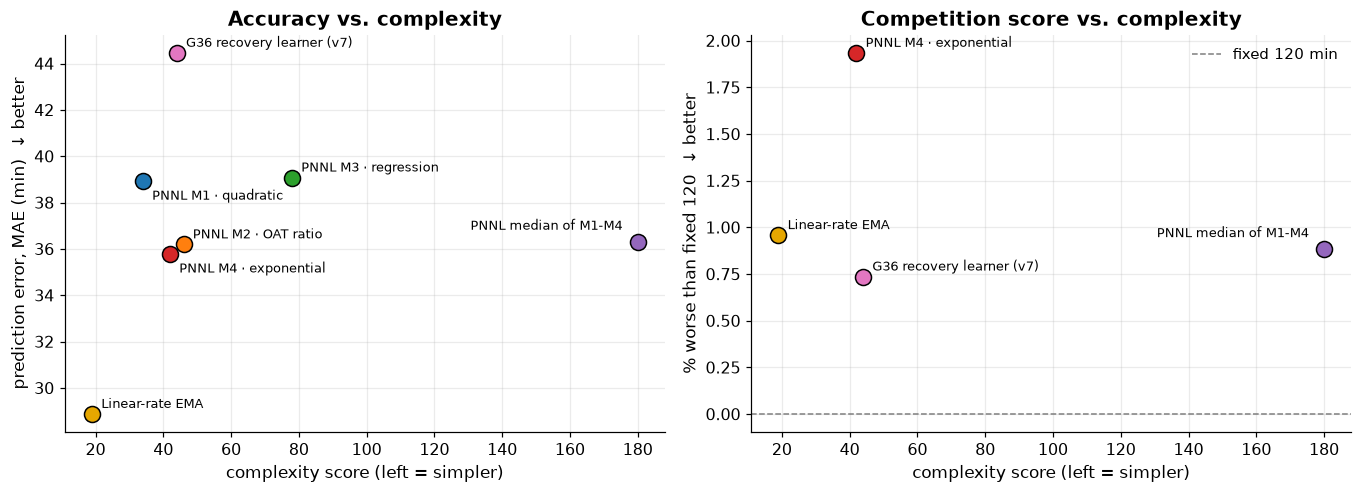

In [25]:
Lb = L.reindex(D2.index)
acc = pd.Series({k: replay_stats(REPLAY[k])["MAE (min)"] for k in D2.index})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
for k in D2.index:
    x = D2.loc[k, "complexity score"]
    a1.scatter(x, acc[k], s=110, color=COLORS[k], edgecolor="k", zorder=3)
    off = {"pnnl_m4_exponential": (6, -12), "pnnl_m1_quadratic": (6, -12), "pnnl_deployed_median_split": (-10, 8)}.get(k, (6, 4))
    a1.annotate(NAMES[k], (x, acc[k]), xytext=off, textcoords="offset points", fontsize=8.5,
                ha="right" if off[0] < 0 else "left")
    if Lb.loc[k, "scenarios"] == 22:
        a2.scatter(x, Lb.loc[k, "comp"], s=110, color=COLORS[k], edgecolor="k", zorder=3)
        a2.annotate(NAMES[k], (x, Lb.loc[k, "comp"]), xytext=(-10, 8) if k == "pnnl_deployed_median_split" else (6, 4),
                    textcoords="offset points", fontsize=8.5, ha="right" if k == "pnnl_deployed_median_split" else "left")
a1.set_xlabel("complexity score (left = simpler)")
a1.set_ylabel("prediction error, MAE (min)  ↓ better"); a1.set_title("Accuracy vs. complexity")
a2.axhline(0, color=COLORS["fixed_120"], ls="--", lw=1, label="fixed 120 min")
a2.set_xlabel("complexity score (left = simpler)"); a2.set_ylabel("% worse than fixed 120  ↓ better")
a2.set_title("Competition score vs. complexity"); a2.legend(loc="upper right")
plt.tight_layout(); plt.show()

<a id="stdlib"></a>
### Best pick when you only have a standard math library

Many controllers and gateways can't install numpy or scipy: plain Python, JavaScript `Math`, Lua `math`, embedded C.
Which algorithm should you pick there?

**Our pick: the linear-rate EMA.** Here's why, from the numbers above:

* **It needs only `+ - * /` and `max`.** Two stored numbers (heating rate, cooling rate), one update per morning, no
  windows, no logs, no matrices. That's about 9 lines in any language.
* **It's the most accurate predictor in the offline replay** (MAE 29 min, vs 36-39 min for the PNNL models and 44 min for
  the v7 rule).
* **It's second-best on energy at equal comfort** (+1.60 % beyond a fixed schedule; only the four-model PNNL median does
  better, at +1.76 %, and that needs all four models running).
* **What you give up:** about 0.2 percentage points of competition score vs. the v7 learner (+0.96 % vs +0.74 % worse than a
  fixed 120-min start), and a bit more lateness than the PNNL median (43 % vs 40 % of mornings). If the competition score is
  what you care about, v7's start rule is the runner-up: also stdlib-only and O(1) memory, but it needs a temperature sample
  every 5 minutes during warm-up.

**What about the PNNL models without numpy?** None of them really needs a library:
* **Model 4** is the only one with a least-squares fit, and it's one variable: $c = \sum e_{i-1}e_i / \sum e_{i-1}^2$.
  Keep two running sums during the warm-up and divide at the end: O(1) memory, no matrix.
* **Models 1 and 3** use two-point fits (first-degree time, then the rest), just arithmetic over the warm-up samples.
* **Model 2** is a ratio. **All four** keep an 8-day window and PNNL's weighted average, which is a short loop.
* The **coast-down stop model** uses 3-parameter recursive least squares: a 3×3 matrix update you can write out by hand
  in about 15 lines, or simplify to a 1-variable fit of the drift rate against (OAT − zone temp) with running sums.

Below: the EMA in stdlib-only Python (checked against the notebook's results), JavaScript (fits a script hook on an IoT
gateway; keep `s` in the platform's persistent storage) and Lua.

In [26]:
# Stdlib-only Python (no imports at all). State is a plain dict you can save as JSON.
def ema_lead(state, mode, temp, target, max_lead=180.0):
    gap = max(0.0, target - temp) if mode == "heat" else max(0.0, temp - target)
    return min(max_lead, gap / max(0.005, state[mode]))

def ema_learn(state, mode, start_temp, target, minutes_taken, w=0.2):
    gap = max(0.0, target - start_temp) if mode == "heat" else max(0.0, start_temp - target)
    if gap > 0 and minutes_taken > 0:
        state[mode] = max(0.005, state[mode] + w * (gap / minutes_taken - state[mode]))
    return state

# Check: replaying the same recorded mornings gives exactly the same predictions as the LinearRateEMA class.
class _StdlibEMA:
    def __init__(self): self.s = {"heat": 0.1, "cool": 0.1}
    def predict(self, mode, temp, target, oat, post_weekend=False): return ema_lead(self.s, mode, temp, target, 1e9)
    def update(self, ev): ema_learn(self.s, ev["mode"], ev["start"], ev["target"], ev["t"])
same = np.allclose(replay(_StdlibEMA).pred.to_numpy(), REPLAY["m0_linear_ema"].pred.to_numpy())
print("stdlib version matches the notebook's EMA on all", len(REPLAY["m0_linear_ema"]), "mornings:", same)

stdlib version matches the notebook's EMA on all 1163 mornings: True


**JavaScript** (no npm packages):

```javascript
const gap = (m, t, sp) => m === "heat" ? Math.max(0, sp - t) : Math.max(0, t - sp);
const emaLead = (s, m, t, sp, maxLead = 180) => Math.min(maxLead, gap(m, t, sp) / Math.max(0.005, s[m]));
function emaLearn(s, m, t0, sp, minutes, w = 0.2) {
  const g = gap(m, t0, sp);
  if (g > 0 && minutes > 0) s[m] = Math.max(0.005, s[m] + w * (g / minutes - s[m]));
  return s;   // s = { heat: 0.1, cool: 0.1 } (°F per minute)
}
```

**Lua** (standard `math` only):

```lua
local function gap(m, t, sp) if m == "heat" then return math.max(0, sp - t) else return math.max(0, t - sp) end end
local function ema_lead(s, m, t, sp, max_lead) return math.min(max_lead or 180, gap(m, t, sp) / math.max(0.005, s[m])) end
local function ema_learn(s, m, t0, sp, minutes, w)
  w = w or 0.2
  local g = gap(m, t0, sp)
  if g > 0 and minutes > 0 then s[m] = math.max(0.005, s[m] + w * (g / minutes - s[m])) end
  return s   -- s = { heat = 0.1, cool = 0.1 }
end
```

<a id="end"></a>
## 12. Takeaways, limitations, use it on your own building, references

### Takeaways
1. **Judge optimal start on more than energy.** Any algorithm can "save energy" by starting late. Ask whether it beats a
   fixed schedule at the same comfort, and check the worst scenario.
2. **Different metrics, different winners.** v7 wins the competition score, the PNNL median wins comfort and energy at
   equal comfort, and the EMA wins accuracy and simplicity.
3. **Simple is competitive.** A two-number EMA is within a fraction of a percent of everything else and runs anywhere.
4. **The PNNL ensemble idea is sound:** the median of four is much safer than any single PNNL model.
5. **Optimal stop is a small, safe win** when the drift model has honest uncertainty bounds.
6. **Mondays are still the hard problem,** exactly as the PNNL field study found.

### Limitations
* **One simulator.** The NeurIPS buildings have strong, fast-recovering VAV systems with reheat; recovery is often 10-20 min.
  Small buildings with rooftop units (the PNNL paper's setting) recover much more slowly, which gives optimal start more room.
* **Online learning from day 1, 30 days per run.** Long-run seasonal behaviour isn't tested.
* **Lateness is measured on the last recoverable zone of each AHU.** Zones that never reach the band (capacity-limited in
  Fairbanks and Minneapolis January) are excluded from lateness but still count in the comfort deficit.
* **The stop experiment covers one building in four climates** with a fixed 120-min start.

### Use it on your own building
1. From your trend logs, extract each morning's warm-up start, the critical zone's temperature trajectory, its setpoint and OAT
   into a table shaped like `recovery_events.csv.gz` / `recovery_traces.csv.gz` (°F, 5-minute samples).
2. Run `replay(LinearRateEMA)` (and the PNNL models) on it and check `replay_stats`: MAE and the share of late starts.
3. Deploy the linear-rate EMA with a clamp (start no earlier than your current schedule, no later than 10 min before
   occupancy) and a post-weekend margin. Log arrival error every morning and keep the fixed schedule as a fallback.
4. For optimal stop, log 5-minute zone temperature while the AHU is off, fit `FirstOrderCoast`, and only allow early stop
   with a guard you're comfortable with (0.2-0.5 °F) and a restart rule.

### References
* W. Kim, M. G. Yu, R. G. Lutes, S. Katipamula. *Implementation and validation of optimal start control strategy for air
  conditioners and heat pumps.* Applied Thermal Engineering 257 (2024) 124256. https://doi.org/10.1016/j.applthermaleng.2024.124256
* Google Smart Buildings simulator (`sbsim`), used by the NeurIPS 2026 Smart Buildings challenge: https://github.com/google/sbsim
* ASHRAE Guideline 36, *High-Performance Sequences of Operation for HVAC Systems.*
* Benchmark code, raw traces and the earlier lessons live in the repository's `archive/pre-strip-2026-11-17` tag:
  https://github.com/bbartling/hvac-optimal-start-math-playground/tree/archive/pre-strip-2026-11-17